# 1.0 Dataset Introduction

The Kepler space telescope was launched by NASA in 2009 to find planets orbiting stars outside our solar system (exoplanets). It found them using the transit method: it continuously measured the brightness of around 150,000 stars and recorded the small, regular dips in light that occur when a planet passes in front of its star. Each repeating dip worth investigating is logged as a Kepler Object of Interest (KOI).

Not every KOI is a planet. Similar dips can be caused by two stars eclipsing each other, by a nearby star contaminating the measurement, or by instrument noise. Each KOI is therefore reviewed and given a disposition: confirmed planet, candidate still awaiting confirmation, or false positive. Doing this by hand is slow, which makes the dataset well suited to machine learning. A model can learn, from the measured properties of the signal and its host star, to separate real planets from false positives.

# 1.1 Dataset Identification

The dataset was retrieved from Kaggle, where it was uploaded under NASA's account as "Kepler Exoplanet Search Results". It is a copy of the Kepler Objects of Interest (KOI) cumulative table, which is published by the NASA Exoplanet Archive (NExScI-Caltech/IPAC, doi:10.26133/NEA4). The table brings together the results of NASA's searches of light curves from the Kepler space telescope. Although the copy was obtained from Kaggle, the data originate from a primary scientific archive and can be checked against it. The dataset can be found at the following URL: 

https://www.kaggle.com/datasets/nasa/kepler-exoplanet-search-results

The dataset contains fifty (50) attributes over 9,564 rows, where each row is one candidate planet. The target is koi_disposition. Four attributes are identifiers and are excluded from modelling, which leaves forty-five (45) features. The attributes are defined as the following types:

- <mark>Categorical (Nominal)</mark>: koi_disposition (CONFIRMED, CANDIDATE, FALSE POSITIVE), koi_pdisposition (CANDIDATE, FALSE POSITIVE), koi_tce_delivname (one of three data releases).
- <mark>Categorical (Binary)</mark>: koi_fpflag_nt, koi_fpflag_ss, koi_fpflag_co, koi_fpflag_ec These are stored as 0/1 flags, each marking a specific reason the signal may be a false positive.
- <mark>Identifiers</mark>: rowid, kepid, kepoi_name, kepler_name These label the object and carry no predictive meaning. kepler_name is only filled for confirmed planets, so 76% of its values are missing.
- <mark>Numerical (Discrete)</mark>: koi_tce_plnt_num The planet's number within its star system, an integer between 1 and 8.
- <mark>Numerical (Continuous)</mark>: koi_score (0 to 1), koi_period, koi_impact, koi_duration, koi_depth, koi_prad, koi_teq, koi_insol, koi_model_snr, koi_steff, koi_slogg, koi_srad, ra, dec and koi_kepmag. Most of these come with an upper (_err1) and lower (_err2) uncertainty, which are also continuous.
- <mark>Time</mark>: koi_time0bk The time of the first observed transit. It is stored as a decimal number of days in Barycentric Kepler Julian Date (BKJD) rather than as a date string, for example 170.53875.
koi_teq_err1 and koi_teq_err2 are entirely empty and koi_score is missing for 16% of rows. koi_score, koi_pdisposition and the four false-positive flags are closely linked to the target, so they should be excluded when classifying koi_disposition. Table 2 summarises the attributes.

| Attribute(s) | Data type | Variable type | Description |
|---|---|---|---|
| rowid, kepid, kepoi_name, kepler_name | Integer / String | Identifier | Row, star and planet identifiers |
| koi_disposition | String | Categorical (nominal) | Target: archive disposition of the candidate |
| koi_pdisposition | String | Categorical (nominal) | Disposition using Kepler data alone |
| koi_tce_delivname | String | Categorical (nominal) | Data release the detection came from |
| koi_fpflag_nt / ss / co / ec | Integer | Categorical (binary) | False-positive flags: not transit-like, stellar eclipse, centroid offset, ephemeris match |
| koi_tce_plnt_num | Float | Numerical (discrete) | Planet number within the system |
| koi_time0bk | Float | Time | Transit epoch (BKJD days) |
| koi_score | Float | Numerical (continuous) | Confidence in the disposition, 0 to 1 |
| koi_period, koi_duration, koi_depth, koi_impact | Float | Numerical (continuous) | Orbital period (days), transit duration (hours), transit depth (ppm), impact parameter |
| koi_prad, koi_teq, koi_insol | Float | Numerical (continuous) | Planet radius (Earth radii), equilibrium temperature (K), insolation flux |
| koi_model_snr | Float | Numerical (continuous) | Transit signal-to-noise ratio |
| koi_steff, koi_slogg, koi_srad, koi_kepmag | Float | Numerical (continuous) | Star temperature (K), surface gravity, radius (Solar radii), Kepler magnitude |
| ra, dec | Float | Numerical (continuous) | Sky coordinates (degrees) |
| *_err1, *_err2 | Float | Numerical (continuous) | Upper and lower uncertainty of the matching attribute |

## 1.2. Supervised Learning Task Identification

**Financial Regression**

**Kepler Objects of Interest**

Herein, the objective of the supervised learning task is to use classification techniques to accurately categorise each Kepler Object of Interest by its disposition (koi_disposition). This can also be determined from the following:

- The target variable, koi_disposition, is categorical (nominal), with three possible classes: CONFIRMED, CANDIDATE and FALSE POSITIVE.
- The features describe measured properties of the transit signal and its host star, which are used to decide whether a signal belongs to a real planet or a false positive.
- The classes are imbalanced, with false positives making up over half of all rows (5,023 of 9,564), which should be taken into account when training and evaluating a model.

A regression task can also be performed on the continuous attributes, such as predicting a planet's radius (koi_prad) from its transit depth and host-star properties. However, classification is the dataset's primary purpose.

## 2 Exploratory Data Analysis

With the identification of the dataset, and the supervised learning task being defined as Kepler Objects of Interest and classification respectively, exploratory data analysis (EDA) can be undertaken to facilitate a deeper understanding of the structure of the data, as well as allowing for identification of issues with data quality (IBM, 2024). This is particularly important for this dataset, as it contains identifier columns, attributes that are entirely empty (koi_teq_err1 and koi_teq_err2), and attributes such as koi_score and the false-positive flags that are closely linked to the target. Furthermore, by creating visualisations of the dataset, it is easier to identify any patterns, trends, or correlations that separate confirmed planets from false positives. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then an explanation of how data will be split into training, validation, and testing sets will be provided; as the classes are imbalanced, the split will be stratified so that each set contains the same proportion of each disposition. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the result support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does transit depth (koi_depth) differ between confirmed planets and false positives? | A common cause of false positives is two stars eclipsing each other, which blocks far more light than a planet. It is expected that false positives will show much greater transit depths than confirmed planets. |
| RQ2 | Does planet radius (koi_prad) differ between confirmed planets and false positives? | As planet radius is calculated from transit depth, it is expected that false positives will show implausibly large radii (larger than the largest known planets), while confirmed planets will mostly be smaller than Jupiter. |
| RQ3 | Does the impact parameter (koi_impact) differ between confirmed planets and false positives? | The impact parameter describes how close to the centre of the star the object passes. It is expected that false positives will more often show high values (above 1), suggesting a grazing eclipse rather than a planet passing in front of the star. |
| RQ4 | Does orbital period (koi_period) impact disposition? | It is expected that confirmed planets will more often have short orbital periods, as these produce more transits during the mission and are therefore easier to confirm. |
| RQ5 | Does the number of planets in a system (koi_tce_plnt_num) impact disposition? | It is expected that objects in systems with more than one candidate are much more likely to be confirmed planets, as it is unlikely for several false signals to occur around the same star (Lissauer et al., 2012). |
| RQ6 | Do the properties of the host star (koi_steff, koi_srad) impact disposition? | It is expected that host-star temperature and radius alone will have little impact on disposition, as planets and false positives can occur around stars of any type. |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
DATA_PATH = "../../datasets/classification/"
kep = pd.read_csv(DATA_PATH + "cumulative.csv")
print(kep.shape)
kep.head()

(9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [3]:
kep.isnull().sum()

rowid                   0
kepid                   0
kepoi_name              0
kepler_name          7270
koi_disposition         0
koi_pdisposition        0
koi_score            1510
koi_fpflag_nt           0
koi_fpflag_ss           0
koi_fpflag_co           0
koi_fpflag_ec           0
koi_period              0
koi_period_err1       454
koi_period_err2       454
koi_time0bk             0
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_impact            363
koi_impact_err1       454
koi_impact_err2       454
koi_duration            0
koi_duration_err1     454
koi_duration_err2     454
koi_depth             363
koi_depth_err1        454
koi_depth_err2        454
koi_prad              363
koi_prad_err1         363
koi_prad_err2         363
koi_teq               363
koi_teq_err1         9564
koi_teq_err2         9564
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
koi_model_snr         363
koi_tce_plnt_num      346
koi_tce_delivname     346
koi_steff   

In [4]:
# Remove identifiers and the target-linked score
kep = kep.drop(columns=["rowid", "kepid", "kepoi_name", "kepler_name", "koi_score"])

# Remove columns that are entirely empty
kep = kep.drop(columns=["koi_teq_err1", "koi_teq_err2"])

# Remove the rows that still have gaps
kep = kep.dropna()

### Split the Dataset

In [5]:
target = "koi_disposition"

leaky = ["koi_pdisposition", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
X = kep.drop([target] + leaky, axis= 1)
y = kep[target]

# Split the dataset into 60% Training data, 40% Temporary dataset with a random state of 42
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=42)

# Further Split the temporary dataset into validation data (20%), testing data (20%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

In [6]:
kep.info()

<class 'pandas.DataFrame'>
Index: 8744 entries, 0 to 9563
Data columns (total 43 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   koi_disposition    8744 non-null   str    
 1   koi_pdisposition   8744 non-null   str    
 2   koi_fpflag_nt      8744 non-null   int64  
 3   koi_fpflag_ss      8744 non-null   int64  
 4   koi_fpflag_co      8744 non-null   int64  
 5   koi_fpflag_ec      8744 non-null   int64  
 6   koi_period         8744 non-null   float64
 7   koi_period_err1    8744 non-null   float64
 8   koi_period_err2    8744 non-null   float64
 9   koi_time0bk        8744 non-null   float64
 10  koi_time0bk_err1   8744 non-null   float64
 11  koi_time0bk_err2   8744 non-null   float64
 12  koi_impact         8744 non-null   float64
 13  koi_impact_err1    8744 non-null   float64
 14  koi_impact_err2    8744 non-null   float64
 15  koi_duration       8744 non-null   float64
 16  koi_duration_err1  8744 non-null   float

In [7]:
unique_values = kep.nunique()
unique_values

koi_disposition         3
koi_pdisposition        2
koi_fpflag_nt           2
koi_fpflag_ss           2
koi_fpflag_co           2
koi_fpflag_ec           2
koi_period           8744
koi_period_err1      7185
koi_period_err2      7185
koi_time0bk          8725
koi_time0bk_err1     2481
koi_time0bk_err2     2481
koi_impact           2170
koi_impact_err1      2014
koi_impact_err2      1673
koi_duration         7355
koi_duration_err1    2234
koi_duration_err2    2234
koi_depth            6679
koi_depth_err1       1382
koi_depth_err2       1382
koi_prad             2878
koi_prad_err1        1753
koi_prad_err2        1536
koi_teq              2467
koi_insol            7485
koi_insol_err1       6922
koi_insol_err2       6374
koi_model_snr        2649
koi_tce_plnt_num        8
koi_tce_delivname       3
koi_steff            2398
koi_steff_err1        264
koi_steff_err2        374
koi_slogg            1530
koi_slogg_err1        541
koi_slogg_err2        419
koi_srad             2245
koi_srad_err

## 2.2 Univariate Analysis

Univariate analysis looks at each attribute on its own: its distribution, its central value and spread, its skew, and any outliers. It is carried out on the **training set only**, so that nothing learnt about the data comes from the validation or test sets. The analysis covers:

1. The distribution of the target, `koi_disposition`.
2. Summary statistics, skewness and outlier counts for the main continuous features.
3. Histograms of each continuous feature, using a log scale where the data cover several orders of magnitude.
4. Box plots to show the spread and outliers.
5. The discrete and categorical features, `koi_tce_plnt_num` and `koi_tce_delivname`.

The `_err1` / `_err2` uncertainty columns are left out here, as they mirror the features they belong to.

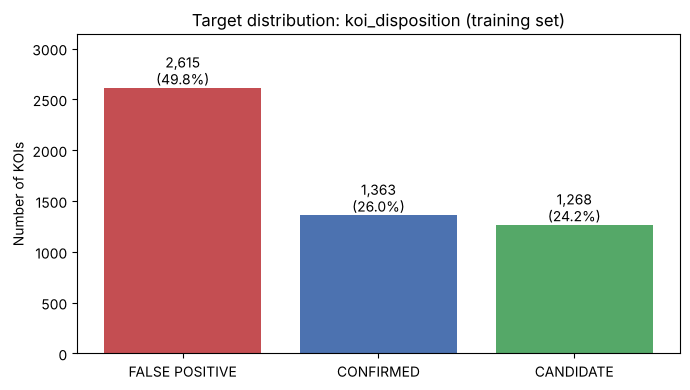

In [8]:
train = X_train.copy()
train["koi_disposition"] = y_train

counts = train["koi_disposition"].value_counts()
share = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=["#C44E52", "#4C72B0", "#55A868"])
for bar, n, p in zip(bars, counts.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p}%)", ha="center", va="bottom")
ax.set_title("Target distribution: koi_disposition (training set)")
ax.set_ylabel("Number of KOIs")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

### 2.2.1 Summary Statistics

The table below gives the usual summary statistics for each continuous feature, with two extra columns:

- **skew**: values near 0 mean a symmetrical distribution. Values above +1 or below −1 mean a heavily skewed one.
- **outliers %**: the share of rows that fall outside 1.5 × the interquartile range (IQR) from the quartiles.

In [9]:
continuous = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_prad", "koi_teq",
              "koi_insol", "koi_model_snr", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

summary = train[continuous].describe().T
summary["median"] = train[continuous].median()
summary["skew"] = train[continuous].skew()

q1, q3 = train[continuous].quantile(0.25), train[continuous].quantile(0.75)
iqr = q3 - q1
outside = (train[continuous] < q1 - 1.5 * iqr) | (train[continuous] > q3 + 1.5 * iqr)
summary["outliers %"] = outside.mean() * 100

summary[["mean", "median", "std", "min", "max", "skew", "outliers %"]].round(2)

,mean,median,std,min,max,skew,outliers %
koi_period,56.20,9.08,117.33,0.30,1064.27,2.88,15.82
koi_duration,5.47,3.81,6.00,0.19,117.52,5.78,8.58
koi_depth,24112.16,424.50,83837.71,4.50,1541400.00,5.49,19.75
koi_impact,0.73,0.53,3.43,0.00,100.20,23.15,0.74
koi_prad,137.76,2.41,3959.41,0.14,200346.00,42.07,15.61
koi_teq,1093.31,885.00,853.71,92.00,13184.00,3.35,4.90
koi_insol,7205.66,145.14,132955.32,0.02,7165673.12,41.25,15.61
koi_model_snr,273.62,23.40,825.03,2.40,9054.70,5.08,17.63
koi_steff,5700.02,5757.50,790.06,2661.00,11360.00,0.53,6.00
koi_slogg,4.30,4.44,0.44,0.11,5.28,-3.39,7.03


### 2.2.2 Distributions

Several features cover many orders of magnitude (for example `koi_depth` ranges from a few ppm to over 1.5 million). On a normal axis almost all values would fall into a single bar, so these features are plotted on a log scale. The dashed line marks the median.

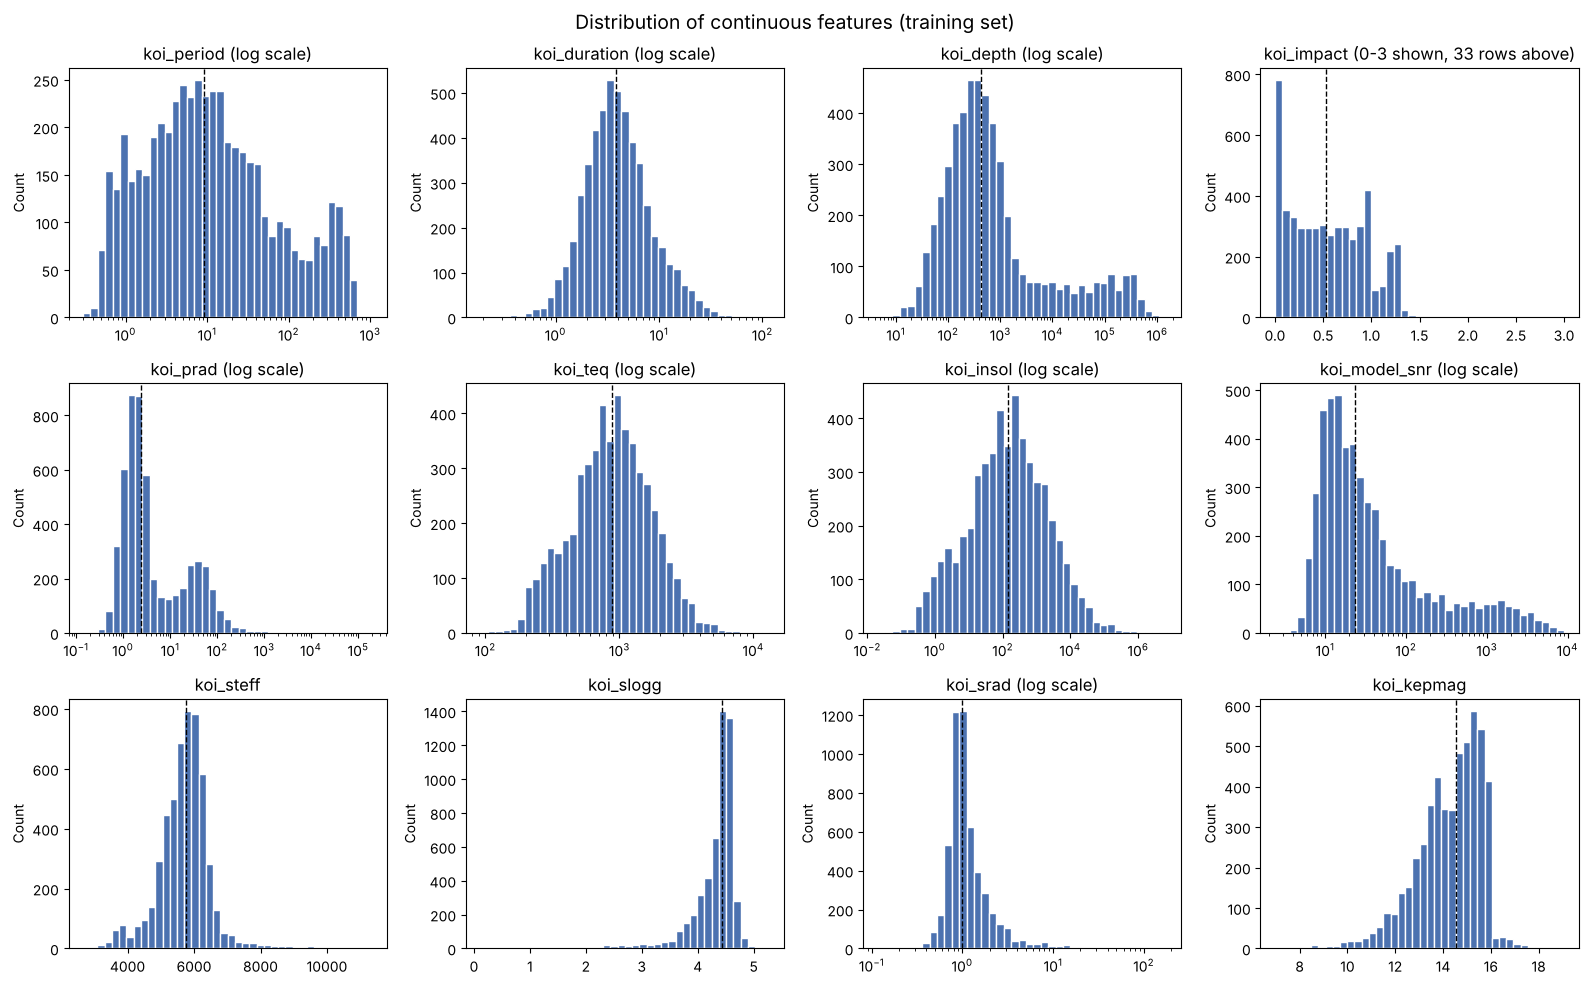

In [10]:
log_scale = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq", "koi_insol", "koi_model_snr", "koi_srad"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, continuous):
    values = train[col]
    if col in log_scale:
        values = values[values > 0]
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 40)
        ax.hist(values, bins=bins, color="#4C72B0", edgecolor="white")
        ax.set_xscale("log")
        ax.set_title(f"{col} (log scale)")
    elif col == "koi_impact":
        # a handful of values reach 100, so zoom to 0-3 where almost all the data lie
        ax.hist(values, bins=np.linspace(0, 3, 40), color="#4C72B0", edgecolor="white")
        ax.set_title(f"koi_impact (0-3 shown, {(values > 3).sum()} rows above)")
    else:
        ax.hist(values, bins=40, color="#4C72B0", edgecolor="white")
        ax.set_title(col)
    ax.axvline(train[col].median(), color="black", linestyle="--", linewidth=1)
    ax.set_ylabel("Count")
plt.suptitle("Distribution of continuous features (training set)", fontsize=14)
plt.tight_layout()
plt.show()

### 2.2.3 Outliers

Box plots show the median, the interquartile range (the box), and the individual points that lie outside 1.5 × IQR. The same log scale is used for the wide-ranging features.

koi_impact > 1 (grazing):           14.1% of rows
koi_prad > 15 Earth radii (> ~1.3 Jupiter): 25.2% of rows
koi_prad > 30 Earth radii (bigger than any known planet):17.8% of rows


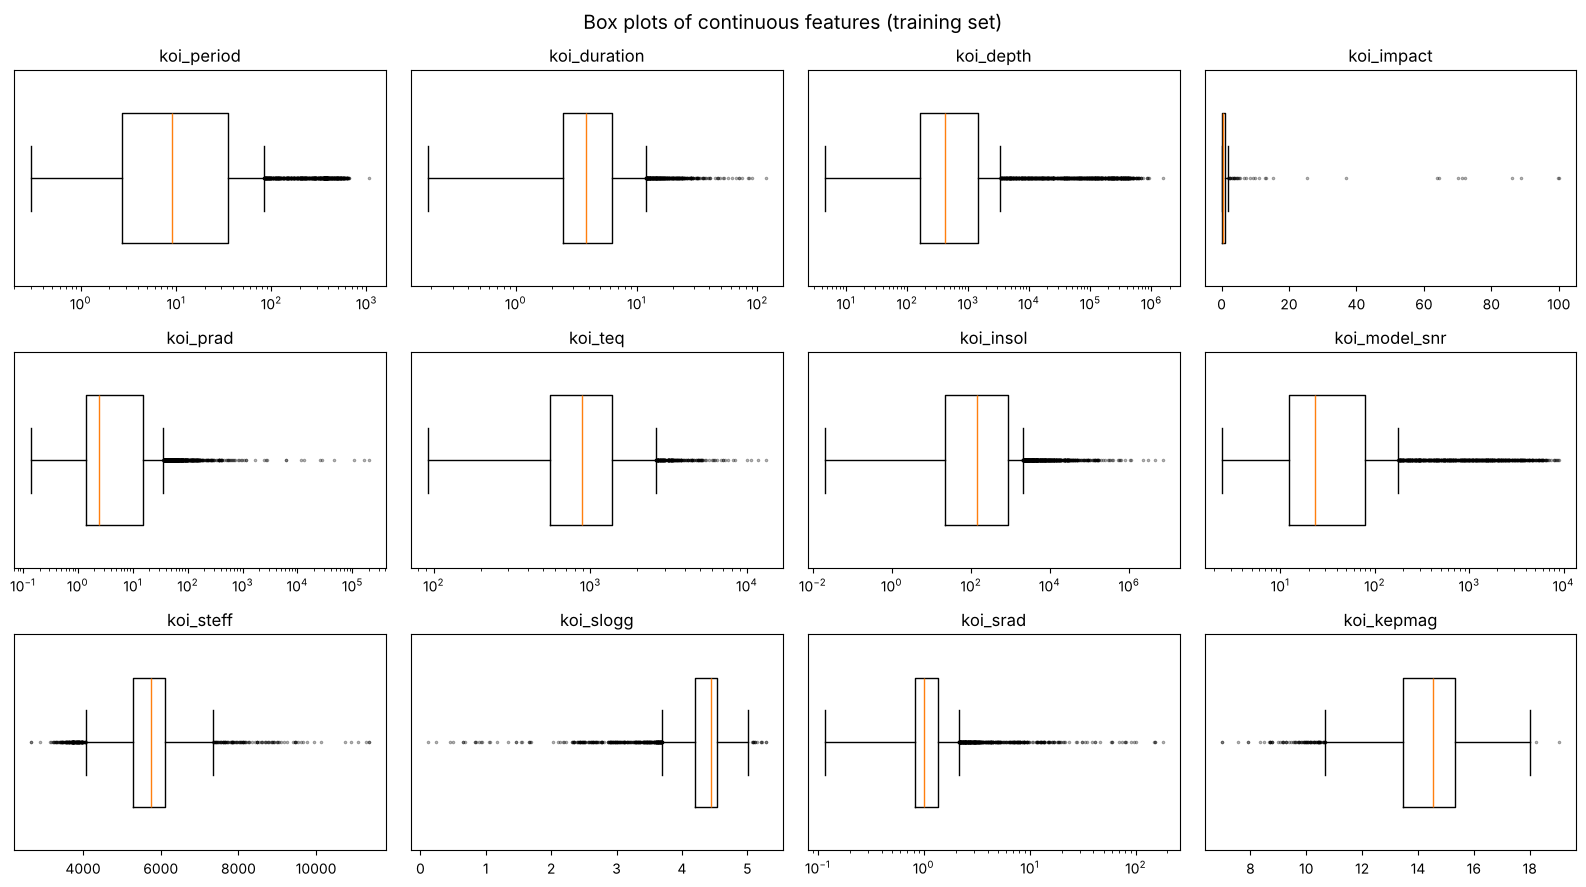

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, continuous):
    values = train[col]
    if col in log_scale:
        values = values[values > 0]
        ax.set_xscale("log")
    ax.boxplot(values, vert=False, widths=0.6, flierprops={"marker": ".", "markersize": 3, "alpha": 0.4})
    ax.set_title(col)
    ax.set_yticks([])
plt.suptitle("Box plots of continuous features (training set)", fontsize=14)
plt.tight_layout()
plt.show()

print(f"koi_impact > 1 (grazing):           {(train['koi_impact'] > 1).mean():.1%} of rows")
print(f"koi_prad > 15 Earth radii (> ~1.3 Jupiter): {(train['koi_prad'] > 15).mean():.1%} of rows")
print(f"koi_prad > 30 Earth radii (bigger than any known planet):{(train['koi_prad'] > 30).mean():.1%} of rows")

### 2.2.4 Discrete and Categorical Features

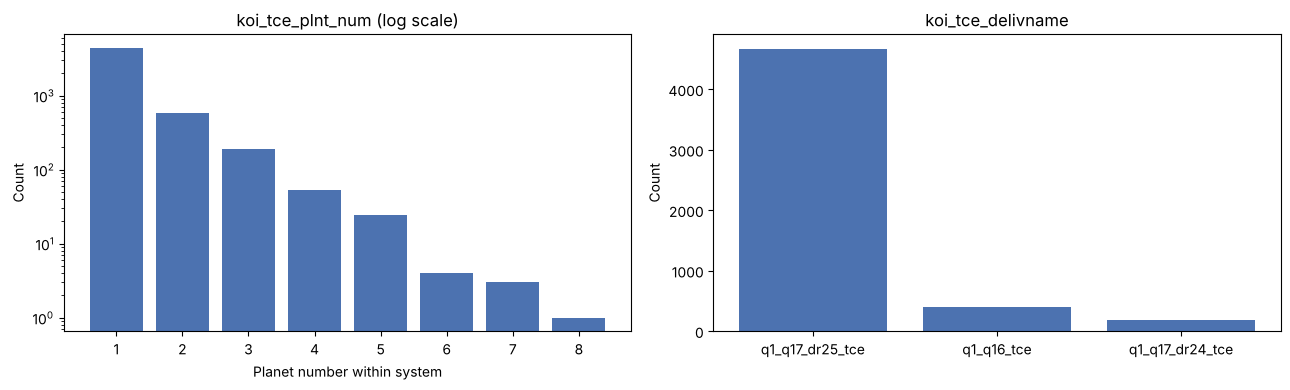

,koi_tce_plnt_num,% of rows
koi_tce_plnt_num,,
1,4393,83.7
2,577,11.0
3,191,3.6
4,53,1.0
5,24,0.5
6,4,0.1
7,3,0.1
8,1,0.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plnt = train["koi_tce_plnt_num"].astype(int).value_counts().sort_index()
axes[0].bar(plnt.index.astype(str), plnt.values, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("koi_tce_plnt_num (log scale)")
axes[0].set_xlabel("Planet number within system")
axes[0].set_ylabel("Count")

deliv = train["koi_tce_delivname"].value_counts()
axes[1].bar(deliv.index, deliv.values, color="#4C72B0")
axes[1].set_title("koi_tce_delivname")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

pd.DataFrame({
    "koi_tce_plnt_num": plnt,
    "% of rows": (plnt / plnt.sum() * 100).round(1),
})

### 2.2.5 Univariate Findings

- **Target:** The classes are imbalanced. FALSE POSITIVE makes up about 50% of the training set, CONFIRMED 26% and CANDIDATE 24%. This supports the stratified split and the use of balanced accuracy and macro F1 in Section 3.
- **Skew:** Most of the signal features are strongly right-skewed. `koi_prad` (skew 42) and `koi_insol` (skew 41) are the most extreme, followed by `koi_impact` (23) and `koi_srad` (19). Their means are far above their medians: the mean `koi_prad` is 137.8 Earth radii but the median is only 2.4, and the mean `koi_depth` is 24,112 ppm against a median of 425. The median is therefore the better summary of a typical KOI. Tree-based models are not affected by skew, but models such as Gaussian Naive Bayes are, which helps explain its weak results in Section 3.2.
- **Two groups in depth and radius (RQ1, RQ2):** On a log scale, `koi_depth` and `koi_prad` both show a main peak (around 100–1,000 ppm and 1–3 Earth radii) and a second, smaller group of very deep, very large signals. 25% of rows have `koi_prad` above 15 Earth radii and 18% above 30, which is larger than any known planet. This second group is likely to be mainly eclipsing binaries, i.e. false positives. Bivariate analysis against the target is needed to confirm this.
- **Impact parameter (RQ3):** Most values lie between 0 and 1, but 14% of rows are above 1, which indicates a grazing transit. A few values reach 100, which is physically implausible, so these are likely to be poor model fits.
- **Orbital period (RQ4):** The median period is 9 days, and 52% of KOIs orbit in under 10 days. This matches the expectation that short periods are easier to detect, because they produce more transits during the mission.
- **Planets per system (RQ5):** 84% of KOIs are the only one detected around their star, 11% are the second and only 1.7% are the fourth or later. Multi-planet systems are a small minority, so this feature can only help for a limited number of rows.
- **Host star (RQ6):** `koi_steff` is roughly symmetrical, centred near 5,760 K (Sun-like stars). `koi_slogg` is left-skewed, with a tail of evolved giant stars, and `koi_srad` is right-skewed for the same reason. `koi_kepmag` is the closest to normal of all the features.
- **Outliers:** Between 15% and 20% of rows are IQR outliers for `koi_period`, `koi_depth`, `koi_prad`, `koi_insol` and `koi_model_snr`. That share is too large to treat as errors: the extreme values are themselves a sign of false positives. They are therefore **kept**, and models that cope well with outliers (decision trees and random forests) are preferred.
- **Data release:** 89% of rows come from the `q1_q17_dr25_tce` release, so `koi_tce_delivname` carries little variation.

## 2.3 Bivariate Analysis

Bivariate analysis looks at attributes two at a time. It has two aims:

1. **Feature vs target:** to find out whether each feature differs between CONFIRMED, CANDIDATE and FALSE POSITIVE. This is what tests the research questions in Section 2.1.
2. **Feature vs feature:** to find features that are strongly correlated with each other and therefore carry the same information.

As before, only the training set is used.

### 2.3.1 Continuous Features by Disposition

Box plots show the distribution of each feature for each class. A log scale is used for the wide-ranging features, so the outliers do not squash the boxes.

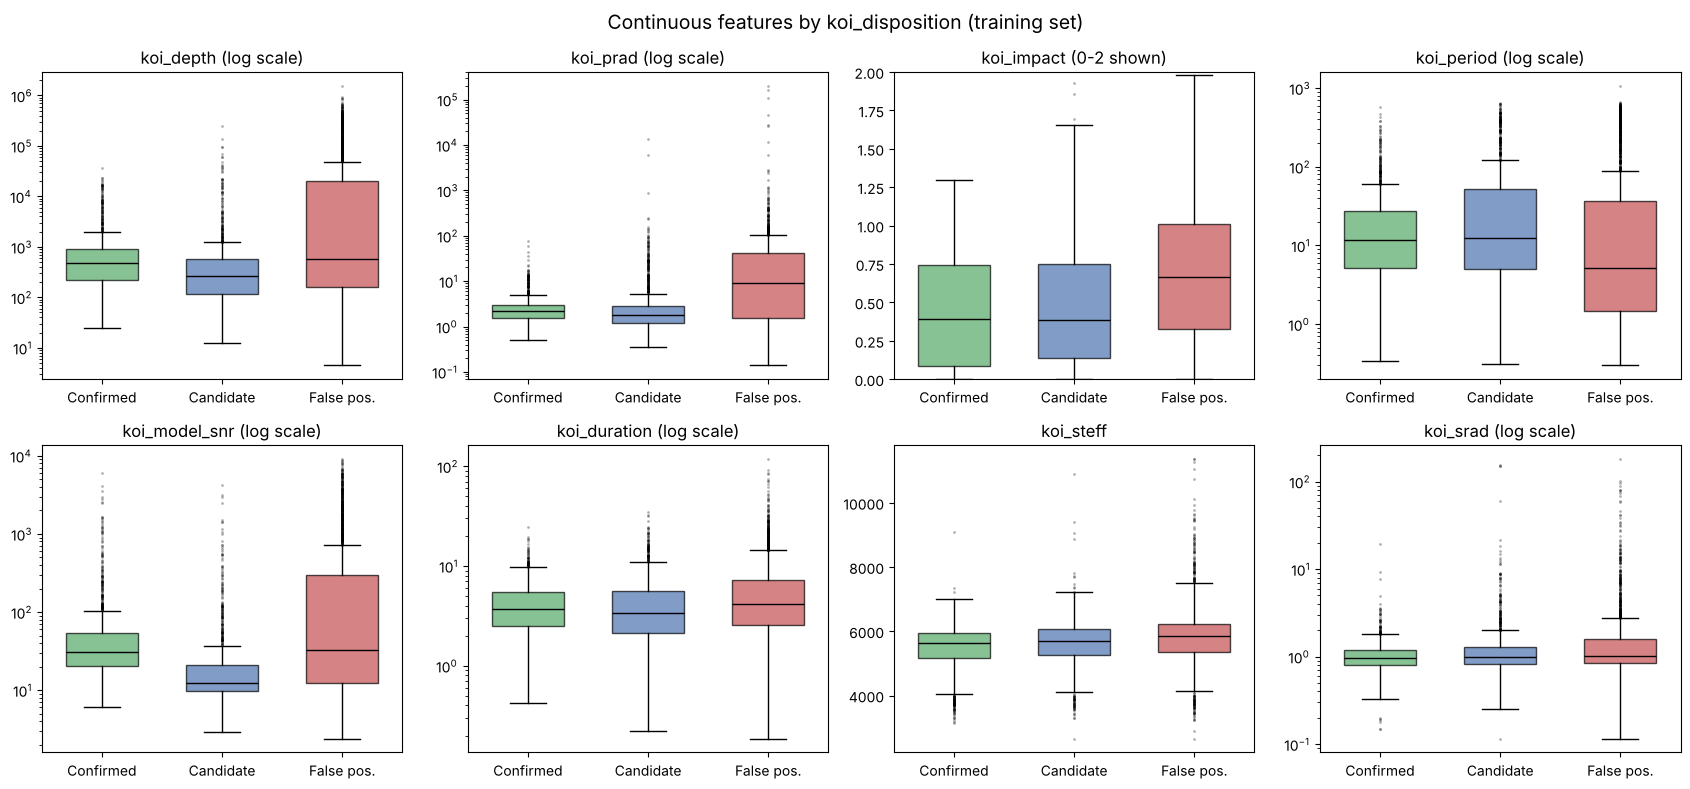

In [13]:
order = ["CONFIRMED", "CANDIDATE", "FALSE POSITIVE"]
colours = {"CONFIRMED": "#55A868", "CANDIDATE": "#4C72B0", "FALSE POSITIVE": "#C44E52"}

plot_features = ["koi_depth", "koi_prad", "koi_impact", "koi_period",
                 "koi_model_snr", "koi_duration", "koi_steff", "koi_srad"]

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flat, plot_features):
    data = [train.loc[train["koi_disposition"] == c, col] for c in order]
    if col in log_scale:
        data = [d[d > 0] for d in data]
        ax.set_yscale("log")
    box = ax.boxplot(data, patch_artist=True, widths=0.6,
                     flierprops={"marker": ".", "markersize": 2, "alpha": 0.3},
                     medianprops={"color": "black"})
    for patch, c in zip(box["boxes"], order):
        patch.set_facecolor(colours[c])
        patch.set_alpha(0.7)
    if col == "koi_impact":
        ax.set_ylim(0, 2)
        ax.set_title("koi_impact (0-2 shown)")
    else:
        ax.set_title(col + (" (log scale)" if col in log_scale else ""))
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Confirmed", "Candidate", "False pos."])
plt.suptitle("Continuous features by koi_disposition (training set)", fontsize=14)
plt.tight_layout()
plt.show()

To check whether the differences in the box plots are statistically significant, a **Kruskal-Wallis test** is used for each feature. It compares the three classes without assuming normal distributions, which suits the heavily skewed features found in Section 2.2. With over 5,000 rows, even small differences produce very small p-values, so an effect size (**epsilon-squared, ε²**) is also reported. Roughly, ε² below 0.01 is negligible, 0.01–0.06 small, 0.06–0.14 medium and above 0.14 large.

In [14]:
from scipy.stats import kruskal, chi2_contingency

n, k = len(train), train["koi_disposition"].nunique()
rows = {}
for col in continuous:
    groups = [g[col] for _, g in train.groupby("koi_disposition")]
    H, p = kruskal(*groups)
    rows[col] = {"H": H, "p-value": p, "ε²": (H - k + 1) / (n - k)}

medians = train.groupby("koi_disposition")[continuous].median().T[order]
medians.columns = ["median: " + c.lower() for c in order]

kw = pd.concat([medians, pd.DataFrame(rows).T], axis=1).sort_values("ε²", ascending=False)
kw.style.format({**{c: "{:.2f}" for c in medians.columns}, "H": "{:.1f}", "p-value": "{:.1e}", "ε²": "{:.3f}"})

,median: confirmed,median: candidate,median: false positive,H,p-value,ε²
koi_model_snr,31.00,12.50,33.00,639.0,1.8e-139,0.121
koi_prad,2.17,1.77,8.93,533.1,1.8e-116,0.101
koi_impact,0.39,0.39,0.67,428.3,9.7e-94,0.081
koi_teq,764.00,788.50,1107.00,281.9,6.1e-62,0.053
koi_insol,80.52,91.23,354.37,281.9,6.1e-62,0.053
koi_depth,476.00,258.85,570.30,275.2,1.8e-60,0.052
koi_period,11.82,12.37,5.20,178.4,1.8e-39,0.034
koi_steff,5629.00,5708.00,5869.00,174.3,1.4e-38,0.033
koi_duration,3.67,3.36,4.14,84.5,4.5e-19,0.016
koi_srad,0.97,0.99,1.02,69.3,8.8e-16,0.013


### 2.3.2 Thresholds from the Research Questions

The research questions make specific claims, for example that very large radii or impact values above 1 indicate a false positive. The chart below shows how the disposition mix changes on either side of each threshold.

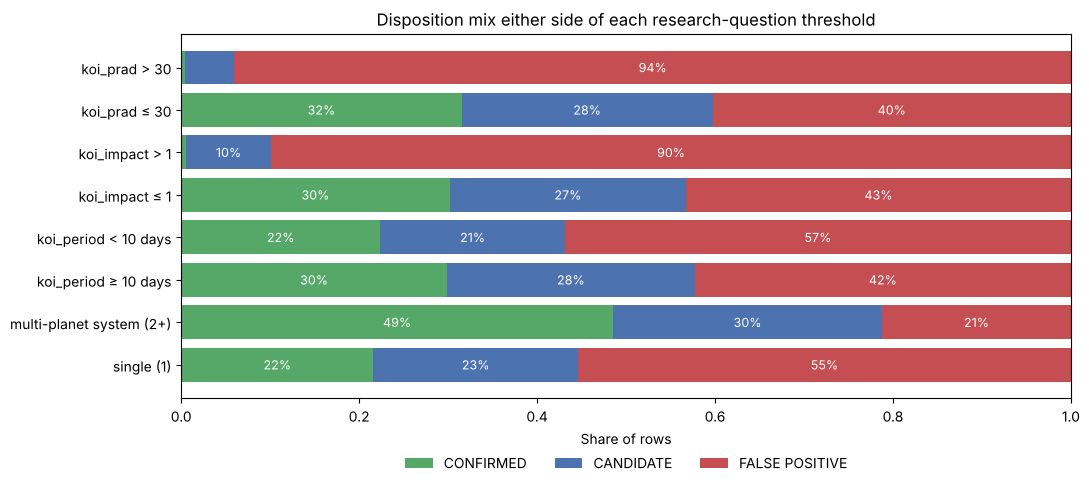

koi_disposition,CONFIRMED,CANDIDATE,FALSE POSITIVE,rows
koi_prad > 30,0.004,0.056,0.940,935
koi_prad ≤ 30,0.315,0.282,0.403,4311
koi_impact > 1,0.005,0.096,0.899,742
koi_impact ≤ 1,0.302,0.266,0.433,4504
koi_period < 10 days,0.224,0.208,0.569,2722
koi_period ≥ 10 days,0.299,0.279,0.423,2524
multi-planet system (2+),0.485,0.302,0.212,853
single (1),0.216,0.230,0.554,4393


In [15]:
conditions = {
    "koi_prad > 30": train["koi_prad"] > 30,
    "koi_prad ≤ 30": train["koi_prad"] <= 30,
    "koi_impact > 1": train["koi_impact"] > 1,
    "koi_impact ≤ 1": train["koi_impact"] <= 1,
    "koi_period < 10 days": train["koi_period"] < 10,
    "koi_period ≥ 10 days": train["koi_period"] >= 10,
    "multi-planet system (2+)": train["koi_tce_plnt_num"] > 1,
    "single (1)": train["koi_tce_plnt_num"] == 1,
}

shares = pd.DataFrame({
    name: train.loc[mask, "koi_disposition"].value_counts(normalize=True)
    for name, mask in conditions.items()
}).T[order].fillna(0)
shares["rows"] = [mask.sum() for mask in conditions.values()]

fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(shares))
for c in order:
    ax.barh(shares.index, shares[c], left=left, color=colours[c], label=c)
    for i, (l, v) in enumerate(zip(left, shares[c])):
        if v > 0.06:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += shares[c].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of rows")
ax.set_title("Disposition mix either side of each research-question threshold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

shares.round(3)

### 2.3.3 Categorical Features by Disposition

For the two categorical features a **chi-square test of independence** is used, with **Cramér's V** as the effect size (0.1 small, 0.3 medium, 0.5 large).

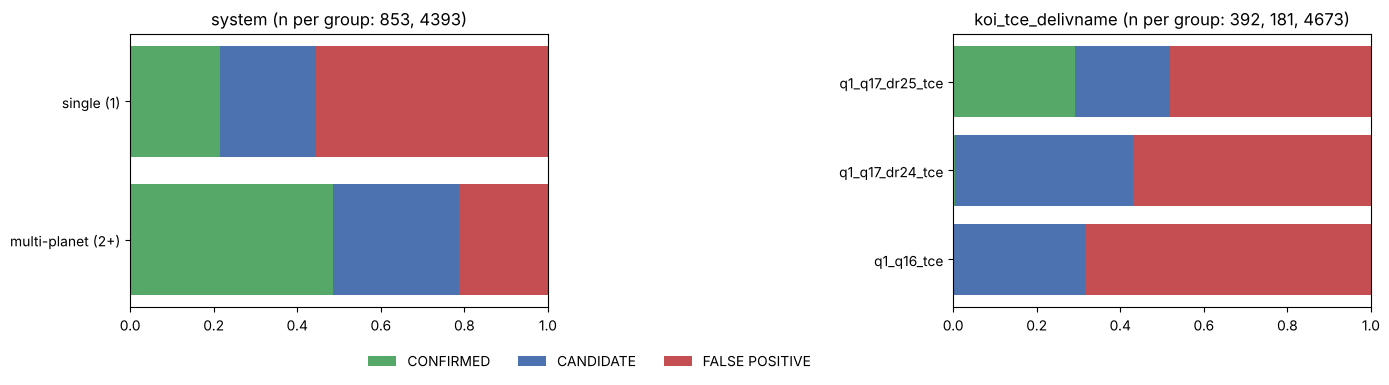

,χ²,p-value,Cramér's V
system,382.4,9.0e-84,0.270
koi_tce_delivname,231.5,6.2e-49,0.149


In [16]:
train["system"] = np.where(train["koi_tce_plnt_num"] > 1, "multi-planet (2+)", "single (1)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
chi_rows = {}
for ax, col in zip(axes, ["system", "koi_tce_delivname"]):
    ct = pd.crosstab(train[col], train["koi_disposition"])[order]
    chi2, p, dof, _ = chi2_contingency(ct)
    chi_rows[col] = {"χ²": chi2, "p-value": p, "Cramér's V": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))}

    pct = ct.div(ct.sum(axis=1), axis=0)
    left = np.zeros(len(pct))
    for c in order:
        ax.barh(pct.index, pct[c], left=left, color=colours[c], label=c)
        left += pct[c].values
    ax.set_xlim(0, 1)
    ax.set_title(f"{col} (n per group: {', '.join(str(v) for v in ct.sum(axis=1))})")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

train = train.drop(columns="system")
pd.DataFrame(chi_rows).T.style.format({"χ²": "{:.1f}", "p-value": "{:.1e}", "Cramér's V": "{:.3f}"})

### 2.3.4 Correlation Between Features

Spearman correlation is used rather than Pearson, because it is based on ranks and so is not distorted by skew or outliers.

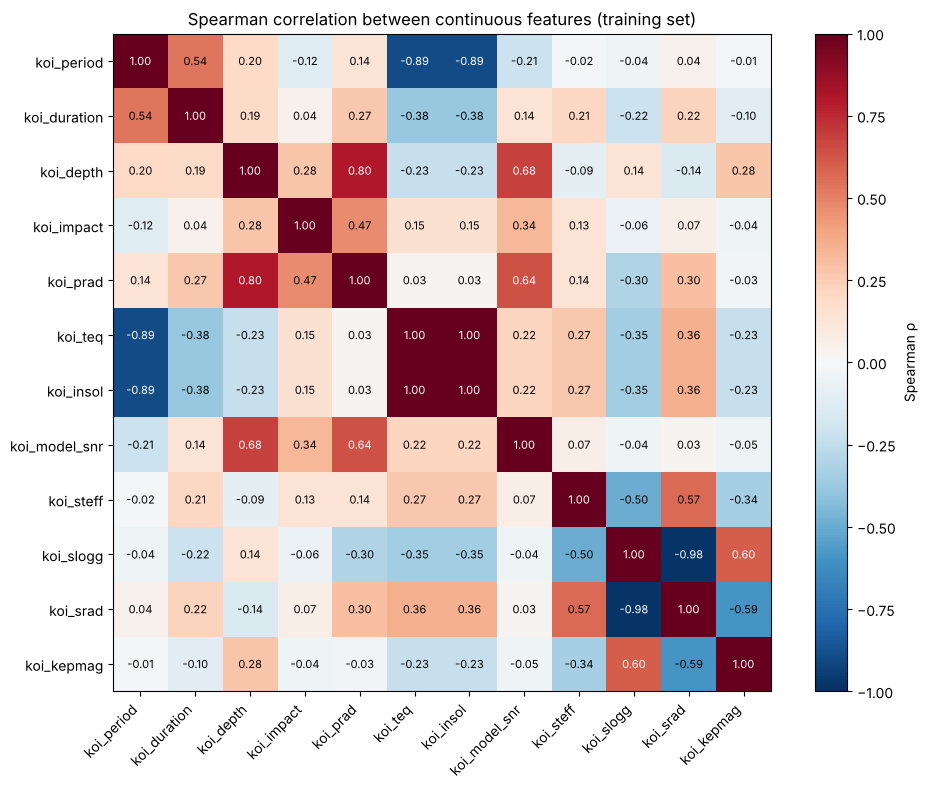

Spearman ρ
koi_teq    koi_insol            1.00
koi_slogg  koi_srad            -0.98
koi_period koi_insol           -0.89
           koi_teq             -0.89
koi_depth  koi_prad             0.80
           koi_model_snr        0.68
koi_prad   koi_model_snr        0.64
koi_slogg  koi_kepmag           0.60

In [17]:
corr = train[continuous].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(continuous)))
ax.set_xticklabels(continuous, rotation=45, ha="right")
ax.set_yticks(range(len(continuous)))
ax.set_yticklabels(continuous)
for i in range(len(continuous)):
    for j in range(len(continuous)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Spearman correlation between continuous features (training set)")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = upper[upper.abs() >= 0.6].sort_values(key=abs, ascending=False)
strong.rename("Spearman ρ").round(2).to_frame()

### 2.3.5 Bivariate Findings and Research Questions

| ID | Result | Evidence (training set) |
|---|---|---|
| RQ1 | **Partly supported** | False positives have a higher median depth (570 ppm against 476 for confirmed planets), but most of the difference is in the tail. Their boxes reach far higher (up to 10⁶ ppm). The effect is small (ε² = 0.052). |
| RQ2 | **Supported** | The median radius is 8.9 Earth radii for false positives against 2.2 for confirmed planets (ε² = 0.101, medium). Of the 935 KOIs with a radius above 30 Earth radii, 94% are false positives and only 0.4% are confirmed. |
| RQ3 | **Supported** | 90% of KOIs with impact above 1 are false positives, against 43% of the rest. The median impact is 0.67 for false positives and 0.39 for both other classes (ε² = 0.081, medium). |
| RQ4 | **Rejected** | The opposite was found. False positives have the *shortest* periods (median 5.2 days, against 11.8 for confirmed planets), and 57% of KOIs with periods under 10 days are false positives. Short-period eclipsing binaries are common, and they make up for the extra transits that short periods provide. |
| RQ5 | **Supported** | 49% of KOIs in multi-planet systems are confirmed, against 22% of single KOIs, and only 21% are false positives (against 55%). This is the strongest categorical relationship (Cramér's V = 0.27). |
| RQ6 | **Largely supported** | The star's radius has a negligible effect (median 0.97–1.02 solar radii in all classes, ε² = 0.013). Star temperature differs slightly (false positives are around 240 K hotter), but the effect is small (ε² = 0.033). |

**Other findings:**

- **The strongest single feature is `koi_model_snr`** (ε² = 0.121). Candidates have a much lower signal-to-noise ratio (median 12.5) than confirmed planets (31.0). This fits the idea that weak signals are harder to confirm, and helps explain why CANDIDATE is the hardest class to predict in Section 3.
- **CANDIDATE sits between the other two classes** on almost every feature, and is closest to CONFIRMED for radius, impact and period. This again shows it is a mixture of planets and false positives that have not yet been resolved.
- **`koi_tce_delivname`** is linked to the target (Cramér's V = 0.15). Almost no confirmed planets come from the two older releases (0.3% and 0.6%, against 29% for DR25). This reflects how the archive was processed rather than anything physical about the planets, so it should be noted as a possible source of bias.
- **Redundant features:** `koi_teq` and `koi_insol` are perfectly correlated (ρ = 1.00), as both are calculated from the star and the orbit. `koi_slogg` and `koi_srad` are almost perfectly negatively correlated (ρ = −0.98). `koi_depth` and `koi_prad` are also strongly linked (ρ = 0.80). Tree-based models are not harmed by this, but one of each pair could be dropped to simplify a model, and these pairs would need to be dealt with before using linear models or Naive Bayes.

## 2.4 Multivariate Analysis

Multivariate analysis looks at three or more attributes together. Bivariate analysis showed that several features each separate the classes to some extent. This section asks:

1. **Do features combine?** For example, are large, grazing signals even more likely to be false positives than signals that are only large or only grazing?
2. **Does a relationship still hold once other features are accounted for?** For example, does the multi-planet effect (RQ5) remain among signals that already look planet-like?
3. **How well do the classes separate when all features are considered together?** This is examined with principal component analysis (PCA).
4. **How much do the features overlap with each other?** This is measured with the variance inflation factor (VIF).

As before, only the training set is used.

### 2.4.1 Feature Combinations by Disposition

Each scatter plot shows two features at once, with the disposition as a third dimension (colour). The dashed lines mark the thresholds from the research questions.

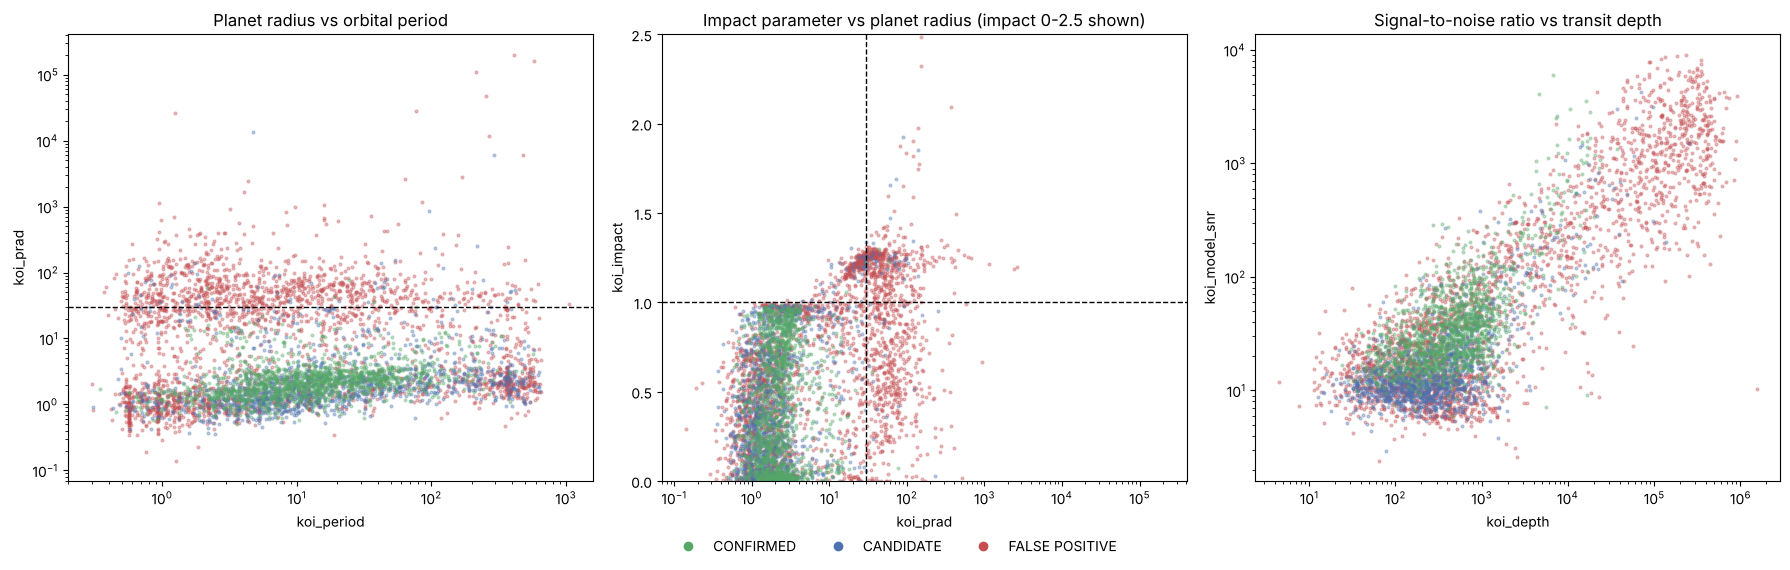

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
pairs = [("koi_period", "koi_prad"), ("koi_prad", "koi_impact"), ("koi_depth", "koi_model_snr")]

# plot false positives first so the smaller classes are drawn on top
for ax, (x, y_col) in zip(axes, pairs):
    for c in ["FALSE POSITIVE", "CANDIDATE", "CONFIRMED"]:
        sub = train[train["koi_disposition"] == c]
        ax.scatter(sub[x], sub[y_col], s=4, alpha=0.35, color=colours[c], label=c)
    ax.set_xscale("log")
    ax.set_xlabel(x)
    ax.set_ylabel(y_col)
    if y_col != "koi_impact":
        ax.set_yscale("log")

axes[0].axhline(30, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Planet radius vs orbital period")
axes[1].axvline(30, color="black", linestyle="--", linewidth=1)
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 2.5)
axes[1].set_title("Impact parameter vs planet radius (impact 0-2.5 shown)")
axes[2].set_title("Signal-to-noise ratio vs transit depth")

handles = [plt.Line2D([], [], marker="o", linestyle="", color=colours[c], label=c) for c in order]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

### 2.4.2 Interaction Between the Research-Question Features

Three yes/no indicators are taken from the research questions: **large** (`koi_prad` > 30), **grazing** (`koi_impact` > 1) and **multi-planet** (`koi_tce_plnt_num` > 1). The table shows the disposition mix for every combination, together with the number of rows in each group. Groups with fewer than 30 rows should be read with caution.

In [19]:
flags = pd.DataFrame({
    "large": train["koi_prad"] > 30,
    "grazing": train["koi_impact"] > 1,
    "multi-planet": train["koi_tce_plnt_num"] > 1,
    "koi_disposition": train["koi_disposition"],
})

combo = (flags.groupby(["large", "grazing", "multi-planet"])["koi_disposition"]
              .value_counts(normalize=True).unstack().reindex(columns=order).fillna(0))
combo["rows"] = flags.groupby(["large", "grazing", "multi-planet"]).size()

combo.style.format({c: "{:.1%}" for c in order}).background_gradient(subset=order, cmap="Greys", vmin=0, vmax=1)

koi_disposition             CONFIRMED  CANDIDATE  FALSE POSITIVE  rows
large grazing multi-planet                                            
False False   False          0.290144   0.287688        0.422168  3257
              True           0.525510   0.309949        0.164541   784
      True    False          0.004132   0.111570        0.884298   242
              True           0.035714   0.321429        0.642857    28
True  False   False          0.004435   0.037694        0.957871   451
              True           0.000000   0.000000        1.000000    12
      True    False          0.002257   0.065463        0.932280   443
              True           0.034483   0.206897        0.758621    29

RQ4 was rejected in the bivariate analysis, because short periods were more often false positives. To check whether this is caused by the large and grazing eclipsing binaries, the period comparison is repeated using only the "planet-like" signals, i.e. those that are neither large nor grazing.

In [20]:
planet_like = ~flags["large"] & ~flags["grazing"]

period_check = pd.DataFrame({
    "All rows: period < 10": train.loc[train["koi_period"] < 10, "koi_disposition"].value_counts(normalize=True),
    "All rows: period ≥ 10": train.loc[train["koi_period"] >= 10, "koi_disposition"].value_counts(normalize=True),
    "Planet-like: period < 10": train.loc[planet_like & (train["koi_period"] < 10), "koi_disposition"].value_counts(normalize=True),
    "Planet-like: period ≥ 10": train.loc[planet_like & (train["koi_period"] >= 10), "koi_disposition"].value_counts(normalize=True),
}).T[order]
period_check["rows"] = [(train["koi_period"] < 10).sum(), (train["koi_period"] >= 10).sum(),
                        (planet_like & (train["koi_period"] < 10)).sum(), (planet_like & (train["koi_period"] >= 10)).sum()]
period_check.style.format({c: "{:.1%}" for c in order})

koi_disposition,CONFIRMED,CANDIDATE,FALSE POSITIVE,rows
All rows: period < 10,22.4%,20.8%,56.9%,2722
All rows: period ≥ 10,29.9%,27.9%,42.3%,2524
Planet-like: period < 10,31.0%,26.5%,42.5%,1961
Planet-like: period ≥ 10,36.1%,31.7%,32.2%,2080


### 2.4.3 Principal Component Analysis (PCA)

PCA combines the 12 continuous features into new uncorrelated axes (principal components), ordered by how much of the variation in the data they capture. Plotting the first two components shows how far the classes separate when all features are considered together.

Before PCA, the wide-ranging features are log-transformed (`koi_impact` uses log(1 + x) because it can be 0), and all features are standardised. Without this, the features with the largest numbers (such as `koi_insol`) would dominate the components. The scaler is fitted on the training set only.

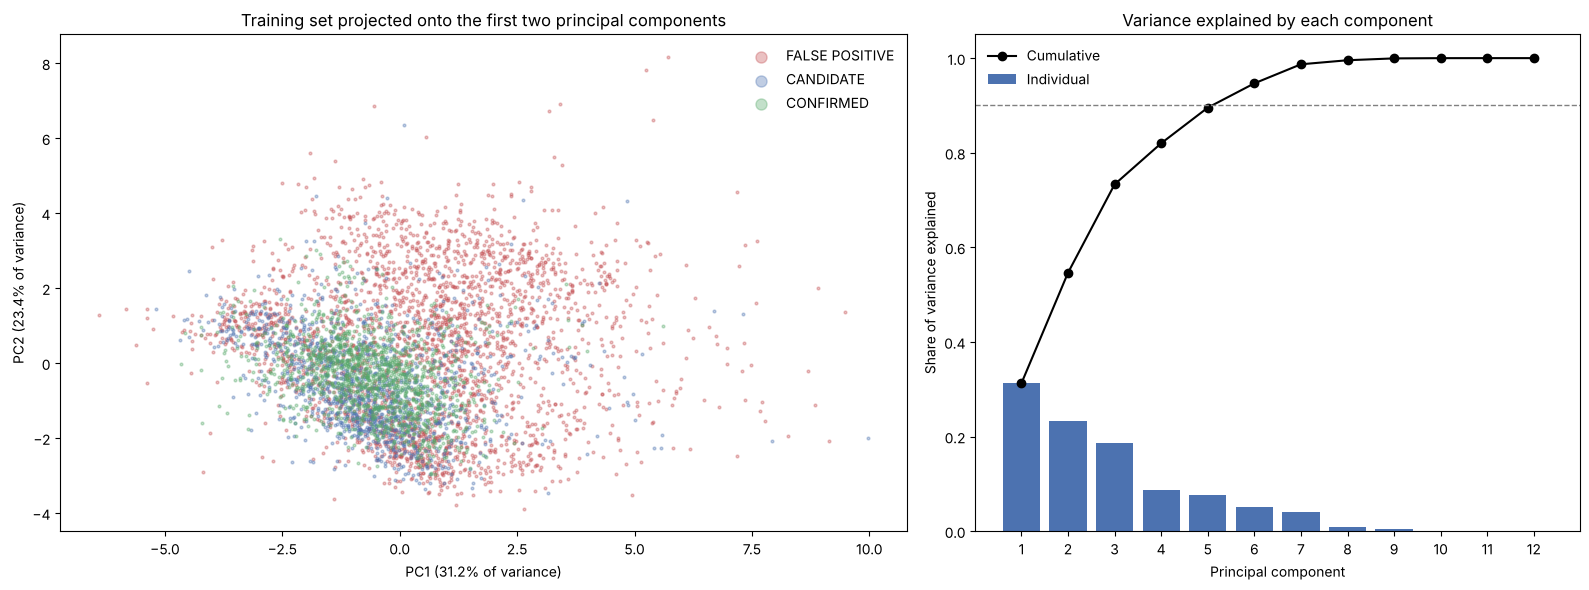

,PC1,PC2
koi_depth,0.09,0.48
koi_prad,0.27,0.46
koi_model_snr,0.20,0.40
koi_duration,-0.09,0.36
koi_period,-0.31,0.30
koi_impact,0.15,0.23
koi_teq,0.46,-0.23
koi_insol,0.46,-0.23
koi_slogg,-0.34,-0.07
koi_srad,0.35,0.07


In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def log_transform(df):
    df = df[continuous].copy()
    df[log_scale] = np.log10(df[log_scale])
    df["koi_impact"] = np.log1p(df["koi_impact"])
    return df

Z = StandardScaler().fit_transform(log_transform(train))
pca = PCA().fit(Z)
pcs = pca.transform(Z)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
for c in ["FALSE POSITIVE", "CANDIDATE", "CONFIRMED"]:
    m = (train["koi_disposition"] == c).values
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.35, color=colours[c], label=c)
axes[0].set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
axes[0].set_title("Training set projected onto the first two principal components")
axes[0].legend(markerscale=4, frameon=False)

steps = np.arange(1, len(explained) + 1)
axes[1].bar(steps, explained, color="#4C72B0", label="Individual")
axes[1].plot(steps, np.cumsum(explained), color="black", marker="o", label="Cumulative")
axes[1].axhline(0.9, color="grey", linestyle="--", linewidth=1)
axes[1].set_xticks(steps)
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Share of variance explained")
axes[1].set_title("Variance explained by each component")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=continuous, columns=["PC1", "PC2"])
loadings.round(2).sort_values("PC2", key=abs, ascending=False)

The loadings show how much each original feature contributes to each component. Large positive or negative values mean the feature has a strong influence on that component.

### 2.4.4 Multicollinearity (Variance Inflation Factor)

The variance inflation factor (VIF) measures how well each feature can be predicted from **all** of the other features combined. This makes it a multivariate extension of the pairwise correlations in Section 2.3.4. A common rule of thumb is that VIF above 10 indicates strong multicollinearity. VIF is calculated on the same log-transformed features, first with all of them, then after removing the redundant features identified in Section 2.3.4.

In [22]:
def vif(df):
    corr = df.corr().values
    return pd.Series(np.diag(np.linalg.inv(corr)), index=df.columns)

Z_df = log_transform(train)
step1 = [c for c in continuous if c not in ["koi_insol", "koi_teq"]]
step2 = [c for c in step1 if c != "koi_slogg"]

vif_table = pd.DataFrame({
    "All features": vif(Z_df),
    "Without koi_insol, koi_teq": vif(Z_df[step1]),
    "Also without koi_slogg": vif(Z_df[step2]),
})
vif_table.style.format("{:.1f}", na_rep="dropped").map(
    lambda v: "background-color: #F4CCCC" if pd.notna(v) and v > 10 else "")

,All features,"Without koi_insol, koi_teq",Also without koi_slogg
koi_depth,11.9,11.8,11.7
koi_duration,1.7,1.7,1.7
koi_impact,2.4,2.4,2.4
koi_insol,391408.8,dropped,dropped
koi_kepmag,1.9,1.9,1.8
koi_model_snr,6.7,6.6,6.6
koi_period,810.6,2.2,2.2
koi_prad,10.2,10.2,10.2
koi_slogg,110.3,80.6,dropped
koi_srad,141.7,86.1,3.1


### 2.4.5 Multivariate Findings

- **Features add to each other.** In the radius vs period plot, almost all false positives above 30 Earth radii form a separate cloud, while confirmed planets stay below the line at all periods. Signals that are both large *and* grazing are 93% false positives, and signals that are planet-like *and* in a multi-planet system are 53% confirmed and only 16% false positives. Combining features separates the classes more clearly than any one of them alone, which is why a model that uses several features at once (such as a Random Forest) is a good fit.
- **RQ5 holds once the other features are accounted for.** Among planet-like signals, being in a multi-planet system still raises the confirmed share from 29% to 53%. The multi-planet effect is therefore not just a side effect of radius or impact.
- **RQ4 is weaker once the other features are accounted for.** Among planet-like signals, the false-positive share for periods under 10 days falls from 57% to 42%, against 32% for longer periods. Much of the bivariate result was caused by short-period eclipsing binaries, which are large and grazing, but a smaller effect in the same direction remains. RQ4 is still rejected.
- **The classes overlap heavily in combined feature space.** The first two principal components explain 54% of the variance, and six components are needed to reach 90%. The last three components explain almost nothing, which confirms that about three of the 12 features are redundant (see 2.4.4). In the PCA plot, false positives spread out along PC2, which is driven mainly by depth, radius and SNR. Confirmed planets and candidates sit almost on top of each other in the centre. No simple straight-line boundary separates the classes, which supports using a non-linear model and explains why CANDIDATE is the hardest class to predict.
- **Several features carry the same information.** With all features included, `koi_teq` and `koi_insol` have VIFs of around 390,000, and `koi_period`, `koi_srad`, `koi_slogg` and `koi_steff` are all above 40. Removing `koi_insol` and `koi_teq` brings `koi_period` and `koi_steff` down to about 2–3. Also removing `koi_slogg` brings `koi_srad` down to 3. This is because temperature and insolation are calculated from the star's properties and the orbital period, so they add no new information. `koi_depth` (≈12) and `koi_prad` (≈10) remain high, as radius is derived from depth. Tree-based models are not affected by this, but these features should be removed or combined before using linear models.

# 3 Classification

With the data cleaned and split, classification models can now be trained to predict `koi_disposition`. Because the classes are imbalanced (false positives make up over half of the rows), accuracy alone can be misleading: a model that always predicts FALSE POSITIVE would already score around 50%. The models are therefore also compared using **balanced accuracy** and **macro-averaged recall and F1**, which give each of the three classes equal weight.

The approach is as follows:

1. Prepare the features so that every model can use them (encode the one remaining text column).
2. Train a baseline and three initial models (Gaussian Naive Bayes, Decision Tree, Random Forest) on the training set and compare them on the validation set.
3. Tune the Random Forest with stratified k-fold cross-validation on the training set.
4. Train and tune four further algorithms (Logistic Regression, K-Nearest Neighbours, Support Vector Machine and Gradient Boosting) in the same way.
5. Select the best tuned model on the validation set and evaluate it once on the held-out test set.

## 3.1 Feature Preparation

`koi_tce_delivname` is the only remaining text feature. It is nominal (three data releases with no order), so it is one-hot encoded. The encoded columns are fixed from the training set and the validation and test sets are aligned to them, so that no information from those sets is used when building the features.

In [23]:
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

def encode(df, columns=None):
    df = pd.get_dummies(df, columns=["koi_tce_delivname"], dtype=int)
    if columns is not None:
        df = df.reindex(columns=columns, fill_value=0)
    return df

X_train_enc = encode(X_train)
X_val_enc = encode(X_val, X_train_enc.columns)
X_test_enc = encode(X_test, X_train_enc.columns)

classes = ["CONFIRMED", "CANDIDATE", "FALSE POSITIVE"]

print("Training:  ", X_train_enc.shape)
print("Validation:", X_val_enc.shape)
print("Testing:   ", X_test_enc.shape)
print()
print(pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True),
}).round(3))

Training:   (5246, 39)
Validation: (1749, 39)
Testing:    (1749, 39)

                 Training  Validation  Testing
koi_disposition                               
FALSE POSITIVE      0.498       0.499    0.498
CONFIRMED           0.260       0.260    0.260
CANDIDATE           0.242       0.242    0.242


The three sets keep the same class proportions, confirming that the stratified split worked as intended.

## 3.2 Baseline and Candidate Models

A `DummyClassifier` that always predicts the most common class is used as a baseline; any useful model must clearly beat it. Three models are then compared:

- **Gaussian Naive Bayes**: a simple probabilistic model that assumes features are independent. It is fast and gives a second, more informed point of reference.
- **Decision Tree**: learns a set of if/then rules. It handles features on very different scales (for example `koi_depth` in ppm and `koi_period` in days) without any scaling.
- **Random Forest**: an ensemble of many decision trees, each trained on a random sample of rows and features. It is usually more accurate and less prone to overfitting than a single tree. `class_weight="balanced"` is used so that the smaller classes are not ignored.

In [24]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "Macro recall": recall_score(y, pred, average="macro"),
        "Macro F1": f1_score(y, pred, average="macro"),
    }

models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
}

results = {}
for name, model in models.items():
    model.fit(X_train_enc, y_train)
    results[name] = evaluate(model, X_val_enc, y_val)

val_results = pd.DataFrame(results).T.round(3)
val_results

,Accuracy,Balanced accuracy,Macro recall,Macro F1
Baseline (most frequent),0.499,0.333,0.333,0.222
Gaussian Naive Bayes,0.397,0.441,0.441,0.341
Decision Tree,0.663,0.627,0.627,0.628
Random Forest,0.770,0.745,0.745,0.739


## 3.3 Hyperparameter Tuning

The Random Forest is tuned with `RandomizedSearchCV`, using 5-fold stratified cross-validation on the training set only, so that the validation and test sets stay unseen. The search optimises macro F1, so that performance on all three classes counts equally.

In [25]:
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": ["balanced", "balanced_subsample", None],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train_enc, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validated macro F1: {search.best_score_:.3f}")

best_rf = search.best_estimator_
val_results.loc["Random Forest (tuned)"] = pd.Series(evaluate(best_rf, X_val_enc, y_val)).round(3)
val_results

Best parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None, 'class_weight': 'balanced'}
Best cross-validated macro F1: 0.733


,Accuracy,Balanced accuracy,Macro recall,Macro F1
Baseline (most frequent),0.499,0.333,0.333,0.222
Gaussian Naive Bayes,0.397,0.441,0.441,0.341
Decision Tree,0.663,0.627,0.627,0.628
Random Forest,0.770,0.745,0.745,0.739
Random Forest (tuned),0.766,0.744,0.744,0.737


## 3.4 Further Classification Algorithms

Four more algorithms are trained and compared:

- **Logistic Regression:** a linear model that estimates the probability of each class from a weighted sum of the features. It is simple and easy to interpret, but it can only draw straight-line (linear) boundaries between the classes.
- **K-Nearest Neighbours (KNN):** classifies each KOI by a majority vote of the *k* most similar KOIs in the training set. It makes no assumptions about the shape of the data, but it relies entirely on distances between points.
- **Support Vector Machine (SVM):** finds the boundary that separates the classes with the widest possible margin. With an RBF kernel it can learn curved, non-linear boundaries.
- **Gradient Boosting:** builds decision trees one after another, with each new tree correcting the errors of the trees before it. scikit-learn's `HistGradientBoostingClassifier` is used. It is the same gradient boosting method as `GradientBoostingClassifier`, but it groups feature values into bins first, which makes training many times faster on a dataset of this size.

**Preprocessing for distance- and scale-based models.** Logistic Regression, KNN and SVM are sensitive to the scale of the features. Without scaling, `koi_insol` (values up to about 7 million) would outweigh `koi_impact` (mostly 0–1). They are also affected by the heavy skew found in Section 2.2. These three models are therefore wrapped in a `Pipeline` that:

1. applies a signed log transform, sign(x) · log(1 + |x|), which reduces skew and still works for the negative `_err2` columns;
2. standardises every feature to mean 0 and standard deviation 1.

Because these steps are inside the pipeline, they are re-fitted on the training part of each cross-validation fold, so no information leaks from the validation folds. Gradient Boosting, like the Random Forest, is tree-based and does not need this preprocessing.

Each model is tuned with `GridSearchCV`, using the same 5-fold stratified cross-validation and macro F1 scoring as the Random Forest. Logistic Regression and SVM use `class_weight="balanced"`, and it is included as an option in the Gradient Boosting grid.

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

def scaled(model):
    return make_pipeline(FunctionTransformer(signed_log), StandardScaler(), model)

candidates = {
    "Logistic Regression": (
        scaled(LogisticRegression(max_iter=5000, class_weight="balanced")),
        {"logisticregression__C": [0.01, 0.1, 1, 10]},
    ),
    "K-Nearest Neighbours": (
        scaled(KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [5, 15, 25, 45],
         "kneighborsclassifier__weights": ["uniform", "distance"]},
    ),
    "Support Vector Machine": (
        scaled(SVC(class_weight="balanced")),
        {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale", 0.01]},
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=42),
        {"learning_rate": [0.05, 0.1], "max_iter": [200, 400],
         "max_depth": [None, 6], "class_weight": [None, "balanced"]},
    ),
}

tuned = {"Random Forest (tuned)": best_rf}
cv_scores = {"Random Forest (tuned)": search.best_score_}

for name, (model, grid) in candidates.items():
    gs = GridSearchCV(model, grid, scoring="f1_macro", cv=cv, n_jobs=-1)
    gs.fit(X_train_enc, y_train)
    tuned[name] = gs.best_estimator_
    cv_scores[name] = gs.best_score_
    val_results.loc[name] = pd.Series(evaluate(gs.best_estimator_, X_val_enc, y_val)).round(3)
    print(f"{name:24s} CV macro F1 = {gs.best_score_:.3f}   best params: {gs.best_params_}")

Logistic Regression      CV macro F1 = 0.698   best params: {'logisticregression__C': 10}
K-Nearest Neighbours     CV macro F1 = 0.670   best params: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'uniform'}
Support Vector Machine   CV macro F1 = 0.729   best params: {'svc__C': 1, 'svc__gamma': 'scale'}
Gradient Boosting        CV macro F1 = 0.747   best params: {'class_weight': 'balanced', 'learning_rate': 0.1, 'max_depth': None, 'max_iter': 400}


### 3.4.1 Model Comparison

The table and chart below bring together every model on the validation set, along with the cross-validated macro F1 from tuning, where the model was tuned.

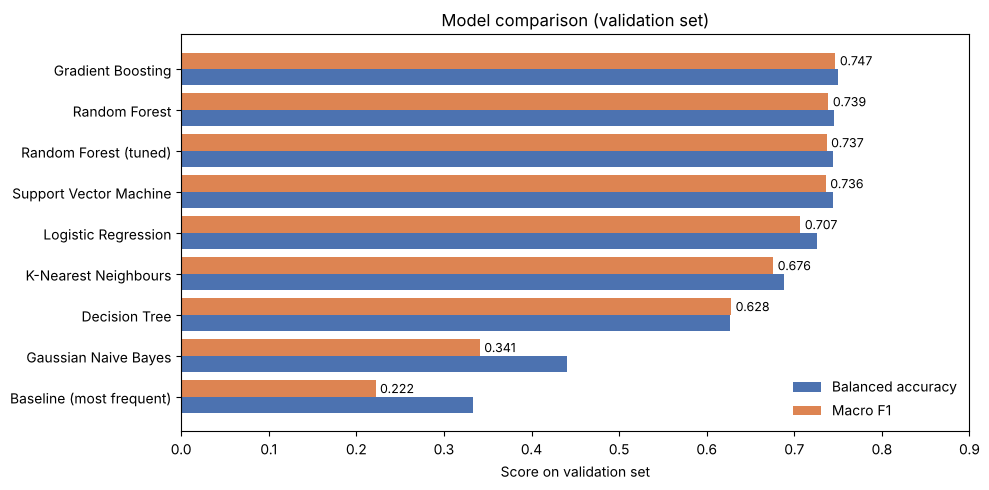

,Accuracy,Balanced accuracy,Macro recall,Macro F1,CV macro F1 (train)
Gradient Boosting,0.780,0.750,0.750,0.747,0.747
Random Forest,0.770,0.745,0.745,0.739,-
Random Forest (tuned),0.766,0.744,0.744,0.737,0.733
Support Vector Machine,0.762,0.744,0.744,0.736,0.729
Logistic Regression,0.725,0.726,0.726,0.707,0.698
K-Nearest Neighbours,0.731,0.688,0.688,0.676,0.670
Decision Tree,0.663,0.627,0.627,0.628,-
Gaussian Naive Bayes,0.397,0.441,0.441,0.341,-
Baseline (most frequent),0.499,0.333,0.333,0.222,-


In [27]:
comparison = val_results.copy()
comparison["CV macro F1 (train)"] = pd.Series(cv_scores).round(3)
comparison = comparison.sort_values("Macro F1", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = comparison[["Balanced accuracy", "Macro F1"]].iloc[::-1]
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.2, plot_df["Balanced accuracy"], height=0.4, color="#4C72B0", label="Balanced accuracy")
ax.barh(y_pos + 0.2, plot_df["Macro F1"], height=0.4, color="#DD8452", label="Macro F1")
for y_, v in zip(y_pos, plot_df["Macro F1"]):
    ax.text(v + 0.005, y_ + 0.2, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0, 0.9)
ax.set_xlabel("Score on validation set")
ax.set_title("Model comparison (validation set)")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

comparison.style.format("{:.3f}", na_rep="-").highlight_max(subset=["Macro F1", "Balanced accuracy", "CV macro F1 (train)"], color="#D9EAD3")

## 3.5 Final Evaluation on the Test Set

The tuned model with the highest validation macro F1 is selected. It is retrained on the training and validation sets combined, so it learns from as much data as possible, and then evaluated once on the test set, which has not been used at any earlier stage.

In [28]:
from sklearn.base import clone

best_name = comparison.loc[list(tuned), "Macro F1"].idxmax()
print("Selected model:", best_name)
print()

X_trainval = pd.concat([X_train_enc, X_val_enc])
y_trainval = pd.concat([y_train, y_val])

final_model = clone(tuned[best_name])
final_model.fit(X_trainval, y_trainval)
y_pred = final_model.predict(X_test_enc)

print(pd.Series(evaluate(final_model, X_test_enc, y_test)).round(3).to_string())
print()
print(classification_report(y_test, y_pred, labels=classes, digits=3))

Selected model: Gradient Boosting

Accuracy             0.780
Balanced accuracy    0.746
Macro recall         0.746
Macro F1             0.744

                precision    recall  f1-score   support

     CONFIRMED      0.773     0.846     0.808       455
     CANDIDATE      0.617     0.522     0.566       423
FALSE POSITIVE      0.849     0.870     0.859       871

      accuracy                          0.780      1749
     macro avg      0.746     0.746     0.744      1749
  weighted avg      0.773     0.780     0.775      1749



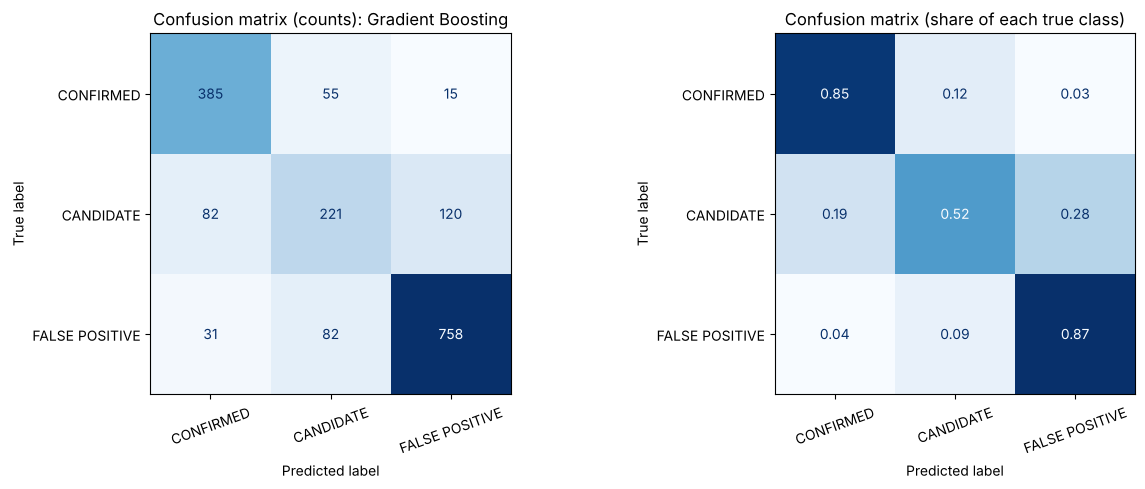

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix (counts): {best_name}")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes, normalize="true", values_format=".2f",
                                        ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix (share of each true class)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 3.5.1 Test-Set Scores for All Tuned Models (for information only)

The model was selected on the validation set alone, and that choice is not changed here. For transparency, every tuned model is also retrained on training + validation and scored on the test set. This shows how much the ranking moves between data splits: if the gaps between models are smaller than this movement, the models should be treated as performing equally well.

In [30]:
test_scores = {}
for name, model in tuned.items():
    m = clone(model).fit(X_trainval, y_trainval)
    test_scores[name] = evaluate(m, X_test_enc, y_test)

test_table = pd.DataFrame(test_scores).T
test_table.insert(0, "Validation macro F1", comparison.loc[list(tuned), "Macro F1"])
test_table.sort_values("Macro F1", ascending=False).round(3)

,Validation macro F1,Accuracy,Balanced accuracy,Macro recall,Macro F1
Random Forest (tuned),0.737,0.786,0.762,0.762,0.756
Gradient Boosting,0.747,0.780,0.746,0.746,0.744
Support Vector Machine,0.736,0.767,0.753,0.753,0.744
Logistic Regression,0.707,0.728,0.729,0.729,0.713
K-Nearest Neighbours,0.676,0.731,0.683,0.683,0.670


## 3.6 Feature Importance

Gradient Boosting and the pipeline-based models do not have a built-in `feature_importances_` attribute in the way the Random Forest does. **Permutation importance** is used instead, which works for any model. Each feature in the test set is shuffled in turn, and the drop in macro F1 is measured. A large drop means the model relies heavily on that feature. A drop near zero means the feature is not needed, often because a correlated feature carries the same information. The shuffle is repeated 10 times per feature, and the bars show the mean and standard deviation.

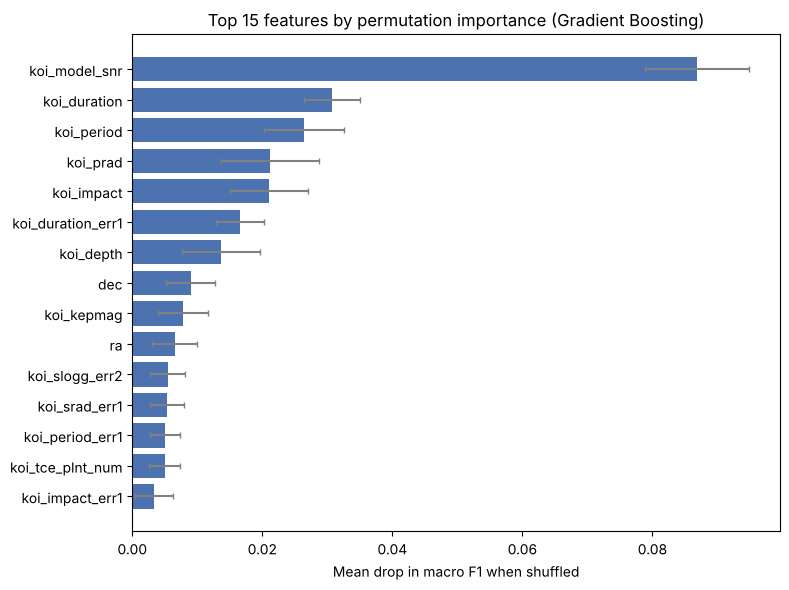

,Importance,Rank (of 39)
koi_period,0.0264,3
koi_prad,0.0212,4
koi_impact,0.0211,5
koi_depth,0.0136,7
koi_tce_plnt_num,0.0050,14
koi_srad,0.0005,28
koi_steff,-0.0035,38


In [31]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test_enc, y_test, scoring="f1_macro",
                              n_repeats=10, random_state=42, n_jobs=-1)
importances = pd.Series(perm.importances_mean, index=X_test_enc.columns).sort_values()
importance_std = pd.Series(perm.importances_std, index=X_test_enc.columns)
top = importances.tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, xerr=importance_std[top.index], color="#4C72B0", ecolor="grey", capsize=2)
ax.set_xlabel("Mean drop in macro F1 when shuffled")
ax.set_title(f"Top 15 features by permutation importance ({best_name})")
plt.tight_layout()
plt.show()

rq_features = ["koi_depth", "koi_prad", "koi_impact", "koi_period", "koi_tce_plnt_num", "koi_steff", "koi_srad"]
rank = importances.rank(ascending=False).astype(int)
pd.DataFrame({"Importance": importances[rq_features].round(4),
              "Rank (of %d)" % len(importances): rank[rq_features]}).sort_values("Importance", ascending=False)

## 3.7 Discussion

**Model comparison.** Nine models were compared on the validation set. Ranked by macro F1:

1. Gradient Boosting: 0.747
2. Random Forest (default): 0.739
3. Random Forest (tuned): 0.737
4. Support Vector Machine: 0.736
5. Logistic Regression: 0.707
6. K-Nearest Neighbours: 0.676
7. Decision Tree: 0.628
8. Gaussian Naive Bayes: 0.341
9. Baseline (most frequent): 0.222

The cross-validated scores from tuning give the same order. The results agree with the EDA:

- **Gradient Boosting, Random Forest and SVM** can all learn non-linear boundaries, and they finish within about 0.01 of each other. Section 2.4.3 showed that this is what the data need, as no straight line separates the classes.
- **Logistic Regression** is limited to linear boundaries and comes about 0.04 lower.
- **KNN** is weakest of the tuned models. It weighs all 39 features equally when measuring distance, including the many weak and redundant ones (Section 2.4.4), so its notion of "similar" is noisy.
- **Gaussian Naive Bayes** is still the weakest model overall, as its independence and normality assumptions are broken by the correlated, skewed features.
- **Tuning** made little difference for the Random Forest, but it mattered more for Gradient Boosting. Its best setting used `class_weight="balanced"`, `learning_rate=0.1` and 400 boosting iterations.

**Test performance.** Gradient Boosting was selected on validation macro F1. Retrained on training + validation data, it scored **78.0% accuracy, 0.746 balanced accuracy and 0.744 macro F1** on the unseen test set, close to its validation score, so it has not overfitted the validation set. By class:

- **FALSE POSITIVE** (F1 0.859) and **CONFIRMED** (F1 0.808) are predicted well. Only 3% of confirmed planets are labelled false positives, and only 4% of false positives are labelled confirmed.
- **CANDIDATE** remains the weak class (F1 0.566). Only 52% of candidates are labelled correctly, while 28% are labelled false positives and 19% confirmed. As in the EDA, this reflects that CANDIDATE is a mixture of planets and false positives that have not yet been resolved, rather than a separate physical category.

**Ranking stability.** Section 3.5.1 shows that, on the test set, the tuned Random Forest (0.756) scores slightly above Gradient Boosting and the SVM (both 0.744), which reverses their order on the validation set. The gaps between these three models (about 0.01) are smaller than the change in each model's own score between the two sets. They should therefore be considered **equally good**. Gradient Boosting is kept as the final model because it was chosen by the planned procedure, and changing the choice after seeing test results would make the test score biased. The clear and stable result is that the non-linear models outperform Logistic Regression, KNN, the single Decision Tree and Naive Bayes.

**Research questions.** Permutation importance (Section 3.6) mostly agrees with the EDA:

- `koi_model_snr` is by far the most important feature, as in Section 2.3.
- **RQ4:** `koi_period` ranks 3rd. The model relies on period heavily, although (as found in the EDA) short periods point towards *false positives*, not confirmed planets.
- **RQ2:** `koi_prad` ranks 4th.
- **RQ3:** `koi_impact` ranks 5th.
- **RQ1:** `koi_depth` ranks 7th. It is useful, but less so than radius, which is derived from it.
- **RQ5:** `koi_tce_plnt_num` ranks 14th, much higher than its built-in Random Forest importance suggested earlier. Impurity-based importance undervalues features with few distinct values, which permutation importance avoids.
- **RQ6:** `koi_srad` (28th) and `koi_steff` (38th, slightly negative) contribute essentially nothing.
- **Other features:** `koi_duration` ranks 2nd, which the research questions did not anticipate. Some uncertainty columns (e.g. `koi_duration_err1`) also rank highly, which suggests the model partly uses how precisely an object has been measured. The sky coordinates `ra` and `dec` appear in the top 10, possibly because the instrument's detectors behave differently across the field of view. Both are worth noting as possible sources of bias rather than physical signals.

**Possible next steps:**

- Remove the redundant features identified in Section 2.4.4 and check that performance holds.
- Combine the three strongest models in a voting ensemble.
- Train a binary model on CONFIRMED vs FALSE POSITIVE only, and use it to score the CANDIDATE objects. This matches how the problem is approached in practice.

# 4 Model Evaluation & Further Modelling Improvements

Section 3 selected a tuned Gradient Boosting model and reported its test-set scores. This section looks more closely at how good that model is, and then tests whether it can be improved.

- **4.1 Model Evaluation:**
  - whether the model ranking is stable across many data splits;
  - ROC and precision-recall curves for each class;
  - a learning curve, to check for over- or under-fitting;
  - how confident the model is when it is right and when it is wrong;
  - whether KOIs from the same star leak information between the training and test data.
- **4.2 Further Improvements:** feature selection, feature engineering, an ensemble, and adjusting the decision rule. Every change is judged by 5-fold cross-validation on the **training set** and checked on the **validation set**, as in Section 3. The test set is not used to choose between them.
- **4.3 Reframing the Problem:** a binary CONFIRMED vs FALSE POSITIVE model, which is then used to score the CANDIDATE objects.
- **4.4 Conclusion.**

## 4.1 Model Evaluation

### 4.1.1 Stability of the Model Ranking

Section 3.5.1 showed that the top three models swapped places between the validation and test sets. To measure how much scores vary from one split to another, the four leading tuned models are compared with **repeated stratified cross-validation** on the combined training + validation data: 5 folds, repeated twice with different shuffles, which gives 10 scores per model. Every model sees exactly the same folds, so their scores can be compared fold by fold (paired).

Gradient Boosting minus Random Forest, fold by fold: mean +0.011, std 0.013, GB better in 8 of 10 folds


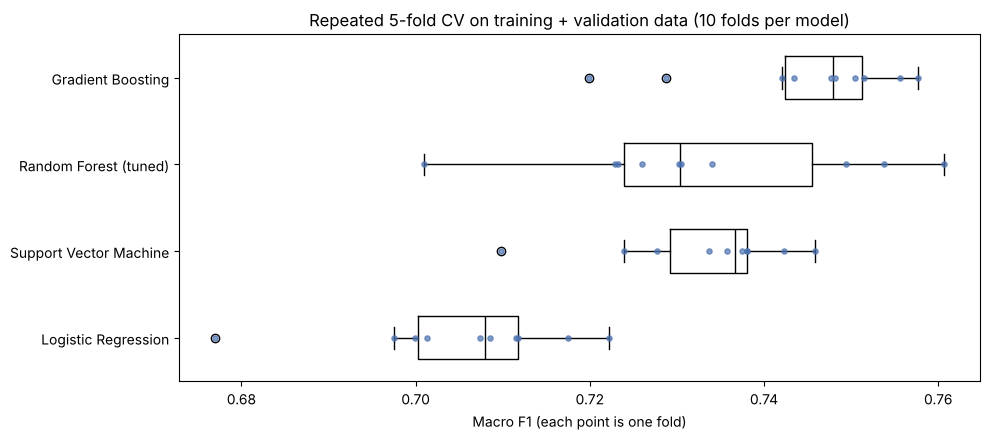

,Mean macro F1,Std,Min,Max
Gradient Boosting,0.745,0.012,0.720,0.758
Random Forest (tuned),0.733,0.017,0.701,0.761
Support Vector Machine,0.733,0.010,0.710,0.746
Logistic Regression,0.705,0.013,0.677,0.722


In [32]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
compare = ["Gradient Boosting", "Random Forest (tuned)", "Support Vector Machine", "Logistic Regression"]

fold_scores = {}
for name in compare:
    fold_scores[name] = cross_val_score(clone(tuned[name]), X_trainval, y_trainval,
                                        cv=rcv, scoring="f1_macro", n_jobs=-1)
fold_scores = pd.DataFrame(fold_scores)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([fold_scores[c] for c in compare], vert=False, widths=0.5, medianprops={"color": "black"})
for i, c in enumerate(compare, start=1):
    ax.scatter(fold_scores[c], np.full(len(fold_scores), i), color="#4C72B0", s=14, alpha=0.7, zorder=3)
ax.set_yticks(range(1, len(compare) + 1))
ax.set_yticklabels(compare)
ax.invert_yaxis()
ax.set_xlabel("Macro F1 (each point is one fold)")
ax.set_title("Repeated 5-fold CV on training + validation data (10 folds per model)")
plt.tight_layout()
plt.show()

stability = pd.DataFrame({
    "Mean macro F1": fold_scores.mean(),
    "Std": fold_scores.std(),
    "Min": fold_scores.min(),
    "Max": fold_scores.max(),
})
diff = fold_scores["Gradient Boosting"] - fold_scores["Random Forest (tuned)"]
print(f"Gradient Boosting minus Random Forest, fold by fold: mean {diff.mean():+.3f}, std {diff.std():.3f}, "
      f"GB better in {(diff > 0).sum()} of {len(diff)} folds")
stability.round(3)

### 4.1.2 ROC and Precision-Recall Curves

Accuracy and F1 only judge the model's final predicted class. ROC and precision-recall curves use the model's predicted **probabilities** instead, and show how well it ranks objects for each class across every possible decision threshold. They are drawn one-vs-rest, i.e. each class against the other two, for the final model on the test set.

- **ROC AUC:** the chance that a randomly chosen object of the class is ranked above a randomly chosen object of another class. 0.5 is random guessing and 1.0 is perfect.
- **Average precision (AP):** summarises the precision-recall curve. For a random model it equals the share of that class (marked by the dashed line), so it is more informative than ROC AUC for the smaller classes.

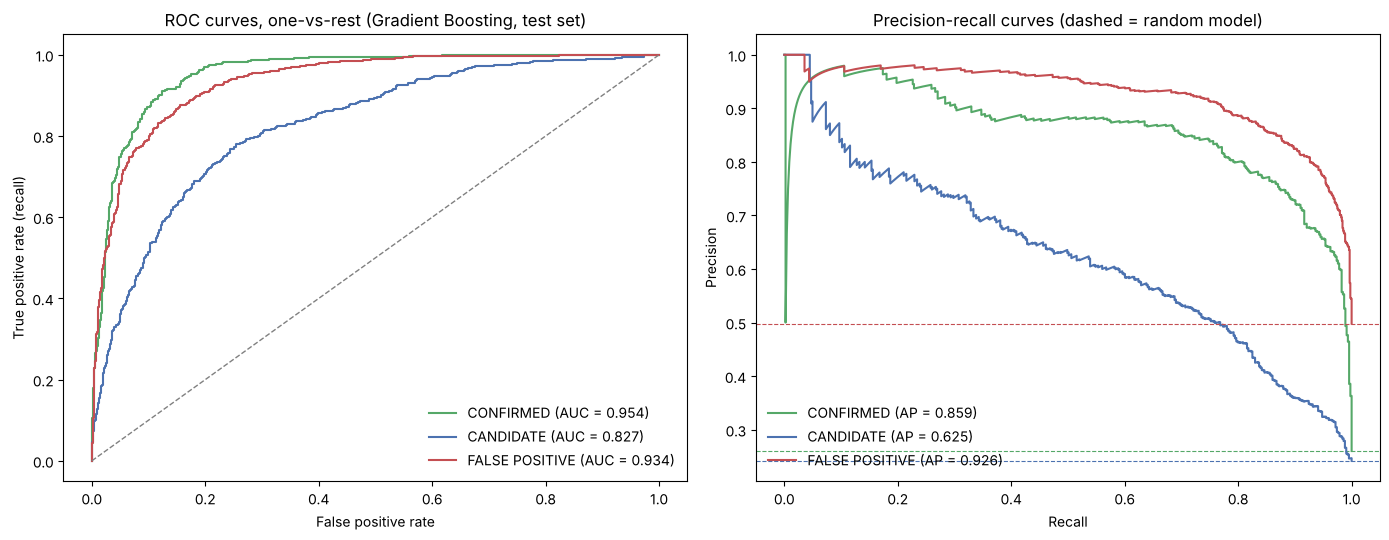

,ROC AUC,Average precision,Class share (random AP)
CONFIRMED,0.954,0.859,0.260
CANDIDATE,0.827,0.625,0.242
FALSE POSITIVE,0.934,0.926,0.498


In [33]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

proba = final_model.predict_proba(X_test_enc)
model_classes = list(final_model.classes_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
auc_rows = {}
for c in order:
    truth = (y_test == c).astype(int)
    p = proba[:, model_classes.index(c)]
    fpr, tpr, _ = roc_curve(truth, p)
    prec, rec, _ = precision_recall_curve(truth, p)
    auc, ap = roc_auc_score(truth, p), average_precision_score(truth, p)
    auc_rows[c] = {"ROC AUC": auc, "Average precision": ap, "Class share (random AP)": truth.mean()}
    axes[0].plot(fpr, tpr, color=colours[c], label=f"{c} (AUC = {auc:.3f})")
    axes[1].plot(rec, prec, color=colours[c], label=f"{c} (AP = {ap:.3f})")
    axes[1].axhline(truth.mean(), color=colours[c], linestyle="--", linewidth=0.8)

axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title(f"ROC curves, one-vs-rest ({best_name}, test set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (dashed = random model)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame(auc_rows).T.round(3)

### 4.1.3 Learning Curve

A learning curve trains the model on increasing amounts of data and compares the score on the data it was trained on with the score on held-out folds.

- A **large gap** between the two lines indicates over-fitting.
- **Both lines low** indicates under-fitting.
- A **validation line still rising** at the right-hand end suggests more data would help.

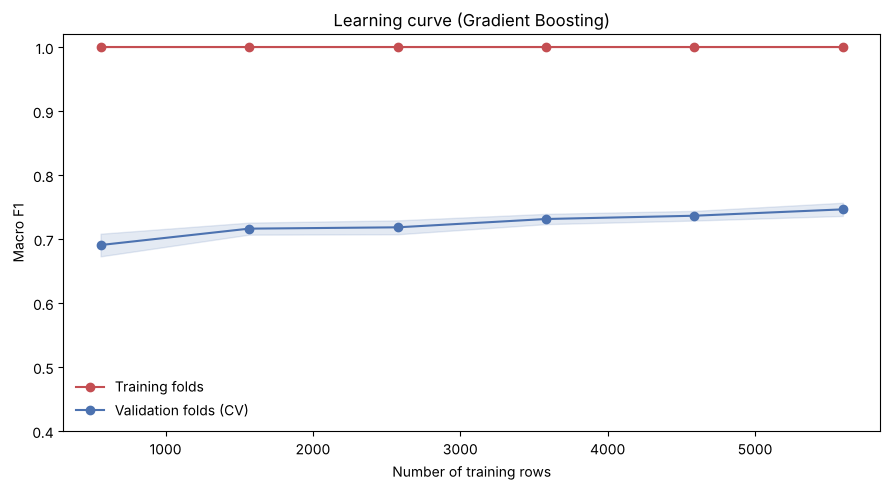

,Training rows,Train F1,CV F1,CV std
0,559,1.0,0.691,0.018
1,1566,1.0,0.716,0.009
2,2574,1.0,0.719,0.011
3,3581,1.0,0.732,0.008
4,4588,1.0,0.737,0.008
5,5596,1.0,0.747,0.010


In [34]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(
    clone(final_model), X_trainval, y_trainval, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
for sc, label, col in [(train_sc, "Training folds", "#C44E52"), (val_sc, "Validation folds (CV)", "#4C72B0")]:
    ax.plot(sizes, sc.mean(axis=1), marker="o", color=col, label=label)
    ax.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=col, alpha=0.15)
ax.set_xlabel("Number of training rows")
ax.set_ylabel("Macro F1")
ax.set_ylim(0.4, 1.02)
ax.set_title(f"Learning curve ({best_name})")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame({"Training rows": sizes, "Train F1": train_sc.mean(axis=1).round(3),
              "CV F1": val_sc.mean(axis=1).round(3), "CV std": val_sc.std(axis=1).round(3)})

### 4.1.4 Prediction Confidence

A useful model should be more confident when it is right than when it is wrong. The chart compares the model's highest predicted probability (its confidence) for correct and incorrect test predictions. The table shows accuracy within confidence bands. If accuracy rises steadily with confidence, the probabilities can be used to flag uncertain objects for manual review.

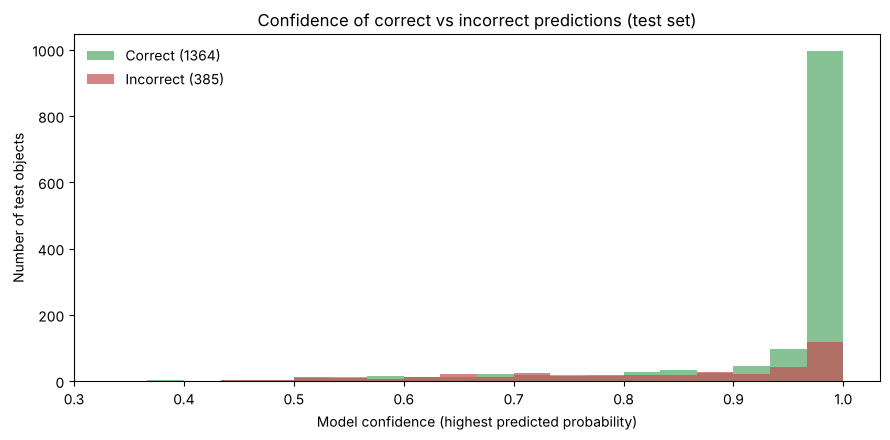

,Objects,Accuracy,Share of CANDIDATE
"(-0.001, 0.6]",81,0.543,0.407
"(0.6, 0.8]",199,0.482,0.422
"(0.8, 0.9]",147,0.571,0.367
"(0.9, 0.95]",134,0.664,0.418
"(0.95, 1.0]",1188,0.885,0.165


In [35]:
confidence = proba.max(axis=1)
correct = (y_pred == y_test.values)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(1 / 3, 1, 21)
ax.hist(confidence[correct], bins=bins, alpha=0.7, color="#55A868", label=f"Correct ({correct.sum()})")
ax.hist(confidence[~correct], bins=bins, alpha=0.7, color="#C44E52", label=f"Incorrect ({(~correct).sum()})")
ax.set_xlabel("Model confidence (highest predicted probability)")
ax.set_ylabel("Number of test objects")
ax.set_title("Confidence of correct vs incorrect predictions (test set)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

band = pd.cut(confidence, [0, 0.6, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
pd.DataFrame({"Objects": pd.Series(band).value_counts().sort_index(),
              "Accuracy": pd.Series(correct).groupby(band, observed=False).mean().round(3).values,
              "Share of CANDIDATE": pd.Series((y_test == "CANDIDATE").values).groupby(band, observed=False).mean().round(3).values})

### 4.1.5 Leakage Check: KOIs from the Same Star

Some stars host several KOIs. These share identical host-star values (`koi_steff`, `koi_srad`, `koi_slogg`, `koi_kepmag`, `ra`, `dec`), and their dispositions are often the same. Because the split in Section 1 was random by row, KOIs from the same star can appear in both the training and test sets. The model could then score well partly by recognising a familiar star rather than learning from the transit signal.

To measure this, the final model is cross-validated twice on the training + validation data, using the same number of folds:

1. **Random folds** (`StratifiedKFold`), as used throughout this notebook.
2. **Grouped folds** (`StratifiedGroupKFold`), which keep all KOIs from the same star (`kepid`) in the same fold, so the model is never tested on a star it has seen.

If the two scores are close, star-level leakage is not inflating the results.

In [36]:
from sklearn.model_selection import StratifiedGroupKFold

# kepid was dropped earlier, so recover it from the original file using the row index
star_id = pd.read_csv(DATA_PATH + "cumulative.csv")["kepid"]
groups_trainval = star_id.loc[X_trainval.index]

multi_star = star_id.loc[kep.index].value_counts()
print(f"Stars with more than one KOI: {(multi_star > 1).sum():,} "
      f"(covering {multi_star[multi_star > 1].sum():,} of {len(kep):,} KOIs)")
shared = star_id.loc[X_test.index].isin(star_id.loc[X_trainval.index])
print(f"Test KOIs whose star also appears in training/validation: {shared.sum()} of {len(X_test)} ({shared.mean():.1%})")
print()

random_cv = cross_val_score(clone(final_model), X_trainval, y_trainval, cv=cv, scoring="f1_macro", n_jobs=-1)
grouped_cv = cross_val_score(clone(final_model), X_trainval, y_trainval, groups=groups_trainval,
                             cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42),
                             scoring="f1_macro", n_jobs=-1)

pd.DataFrame({
    "Mean macro F1": [random_cv.mean(), grouped_cv.mean()],
    "Std": [random_cv.std(), grouped_cv.std()],
}, index=["Random folds (StratifiedKFold)", "Grouped by star (StratifiedGroupKFold)"]).round(3)

Stars with more than one KOI: 825 (covering 2,019 of 8,744 KOIs)
Test KOIs whose star also appears in training/validation: 359 of 1749 (20.5%)



,Mean macro F1,Std
Random folds (StratifiedKFold),0.747,0.010
Grouped by star (StratifiedGroupKFold),0.737,0.007


Of the 8,744 KOIs, 2,019 belong to one of the 825 stars that host more than one KOI, and 20.5% of test KOIs share a star with the training or validation data. Keeping each star's KOIs together lowers the cross-validated macro F1 from 0.747 to 0.737. This drop of 0.010 is about the size of the normal fold-to-fold variation (± 0.007–0.010). Star-level leakage therefore inflates the reported scores only slightly, by about one percentage point at most, and does not change any conclusion. A fully leakage-free estimate of the three-class model's performance is around 0.74 macro F1.

## 4.2 Further Modelling Improvements

Each improvement below is applied to the selected model (Gradient Boosting with the tuned settings from Section 3.4), so that any change in score comes from the improvement itself. Each version is scored with the same 5-fold stratified cross-validation on the training set and then checked once on the validation set.

The fold-to-fold standard deviation (about ±0.01–0.02) gives a sense of how much scores move by chance. A change is only treated as a real improvement if it beats the baseline by clearly more than this on **both** the cross-validation and the validation set.

The experiments are:

| Experiment | Idea | Motivation |
|---|---|---|
| Remove redundant features | Drop `koi_insol`, `koi_teq` and `koi_slogg` | VIF analysis (2.4.4): these are almost fully determined by other features |
| Remove possible bias features | Drop `ra`, `dec` and `koi_tce_delivname` | Sections 2.3 and 3.6: these may reflect how the data were collected or processed rather than physics |
| Remove uncertainty columns | Drop all `_err1` / `_err2` columns | Halves the number of features. Tests how much the model relies on measurement precision |
| Feature engineering | Add physically motivated features (below) | Gives the model relationships that the transit method predicts for a genuine planet |
| Feature engineering + remove redundant | Both of the above | |
| Soft-voting ensemble | Average the probabilities of the tuned Random Forest and Gradient Boosting | The two models were tied in 4.1.1; averaging can reduce errors that only one of them makes |

**Engineered features:**

- **`duration_ratio`:** the observed transit duration divided by the duration expected for a planet on a circular orbit, given the orbital period and the star's density. The expected duration is approximately 13 h × (P / 365 days)^(1/3) × (ρ★ / ρ☉)^(−1/3), and the star's density is estimated from `koi_slogg` and `koi_srad`. A genuine planet should give a ratio near 1. Eclipsing binaries and blends often do not.
- **`snr_per_transit`:** `koi_model_snr` divided by the square root of the approximate number of transits Kepler observed (about 1,460 days / period). This separates a strong individual signal from one that is only detectable because it repeats many times.
- **`prad_rel_err`, `depth_rel_err`:** the relative uncertainty of the planet radius and the transit depth. These measure how precisely each object has been characterised, independent of its size.

In [37]:
def add_features(df):
    df = df.copy()
    density = 10 ** (df["koi_slogg"] - 4.438) / df["koi_srad"]  # stellar density relative to the Sun
    expected_duration = 13 * (df["koi_period"] / 365.25) ** (1 / 3) * density ** (-1 / 3)
    df["duration_ratio"] = df["koi_duration"] / expected_duration
    df["snr_per_transit"] = df["koi_model_snr"] / np.sqrt(np.maximum(1460 / df["koi_period"], 1))
    df["prad_rel_err"] = df["koi_prad_err1"] / df["koi_prad"]
    df["depth_rel_err"] = df["koi_depth_err1"] / df["koi_depth"]
    return df

redundant = ["koi_insol", "koi_teq", "koi_slogg"]
bias = ["ra", "dec"] + [c for c in X_train_enc.columns if c.startswith("koi_tce_delivname")]
errors = [c for c in X_train_enc.columns if "_err" in c]

feature_sets = {
    "Baseline (all 39 features)": lambda d: d,
    "Remove redundant features": lambda d: d.drop(columns=redundant),
    "Remove possible bias features": lambda d: d.drop(columns=bias),
    "Remove uncertainty columns": lambda d: d.drop(columns=errors),
    "Feature engineering": add_features,
    "Feature engineering + remove redundant": lambda d: add_features(d).drop(columns=redundant),
}

# check the new features behave as expected: genuine planets should have duration_ratio near 1
eng = add_features(X_train_enc)
print("Median duration_ratio by class:")
print(eng.groupby(y_train)["duration_ratio"].median().reindex(order).round(2).to_string())
print()

base_model = tuned[best_name]
experiments = {}
for name, transform in feature_sets.items():
    Xa, Xb = transform(X_train_enc), transform(X_val_enc)
    scores = cross_val_score(clone(base_model), Xa, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    val_f1 = f1_score(y_val, clone(base_model).fit(Xa, y_train).predict(Xb), average="macro")
    experiments[name] = {"Features": Xa.shape[1], "CV macro F1": scores.mean(), "CV std": scores.std(), "Validation macro F1": val_f1}
    print(f"{name:42s} CV {scores.mean():.3f} ± {scores.std():.3f}   validation {val_f1:.3f}")

Median duration_ratio by class:
koi_disposition
CONFIRMED         0.91
CANDIDATE         0.78
FALSE POSITIVE    1.09

Baseline (all 39 features)                 CV 0.747 ± 0.012   validation 0.747
Remove redundant features                  CV 0.743 ± 0.012   validation 0.743
Remove possible bias features              CV 0.729 ± 0.014   validation 0.743
Remove uncertainty columns                 CV 0.729 ± 0.009   validation 0.739
Feature engineering                        CV 0.742 ± 0.020   validation 0.749
Feature engineering + remove redundant     CV 0.747 ± 0.014   validation 0.751


In [38]:
from sklearn.ensemble import VotingClassifier

voting = VotingClassifier([("rf", clone(tuned["Random Forest (tuned)"])), ("gb", clone(base_model))], voting="soft")
scores = cross_val_score(voting, X_train_enc, y_train, cv=cv, scoring="f1_macro")
val_f1 = f1_score(y_val, clone(voting).fit(X_train_enc, y_train).predict(X_val_enc), average="macro")
experiments["Soft-voting ensemble (RF + GB)"] = {"Features": X_train_enc.shape[1], "CV macro F1": scores.mean(),
                                                  "CV std": scores.std(), "Validation macro F1": val_f1}
print(f"Soft-voting ensemble (RF + GB)  CV {scores.mean():.3f} ± {scores.std():.3f}   validation {val_f1:.3f}")

Soft-voting ensemble (RF + GB)  CV 0.749 ± 0.011   validation 0.752


### 4.2.1 Adjusting the Decision Rule

By default, the model predicts whichever class has the highest probability. Because CANDIDATE is the weakest class, it may help to scale up its probability, or scale down another class's, before choosing. The best multipliers are found on **out-of-fold** probabilities from cross-validation on the training set, i.e. predictions for rows the model was not trained on. They are then checked on the validation set.

In [39]:
from sklearn.model_selection import cross_val_predict
import itertools

oof = cross_val_predict(clone(base_model), X_train_enc, y_train, cv=cv, method="predict_proba", n_jobs=-1)
cls = np.array(sorted(y_train.unique()))  # CANDIDATE, CONFIRMED, FALSE POSITIVE (the model's column order)

best_f1, best_w = 0, None
for w_cand, w_fp in itertools.product(np.arange(0.6, 2.01, 0.05), repeat=2):
    w = np.array([w_cand, 1.0, w_fp])
    f = f1_score(y_train, cls[(oof * w).argmax(axis=1)], average="macro")
    if f > best_f1:
        best_f1, best_w = f, w

base_oof = f1_score(y_train, cls[oof.argmax(axis=1)], average="macro")
val_proba = clone(base_model).fit(X_train_enc, y_train).predict_proba(X_val_enc)
val_base = f1_score(y_val, cls[val_proba.argmax(axis=1)], average="macro")
val_adj = f1_score(y_val, cls[(val_proba * best_w).argmax(axis=1)], average="macro")

print(f"Best multipliers: CANDIDATE × {best_w[0]:.2f}, CONFIRMED × 1.00, FALSE POSITIVE × {best_w[2]:.2f}")
print(f"Out-of-fold macro F1: {base_oof:.3f} -> {best_f1:.3f}")
print(f"Validation macro F1:  {val_base:.3f} -> {val_adj:.3f}")

experiments["Adjusted decision rule"] = {"Features": X_train_enc.shape[1], "CV macro F1": best_f1,
                                          "CV std": np.nan, "Validation macro F1": val_adj}

Best multipliers: CANDIDATE × 1.50, CONFIRMED × 1.00, FALSE POSITIVE × 0.85
Out-of-fold macro F1: 0.747 -> 0.751
Validation macro F1:  0.747 -> 0.748


### 4.2.2 Summary of Improvements

The chart shows the change in macro F1 against the baseline for each experiment. The error bars show ± one fold-to-fold standard deviation of the baseline: changes inside the grey band are within normal variation and cannot be told apart from chance.

For the adjusted decision rule, the CV figure is the out-of-fold score that the multipliers were tuned on, so it is optimistic. The validation figure is the fair comparison.

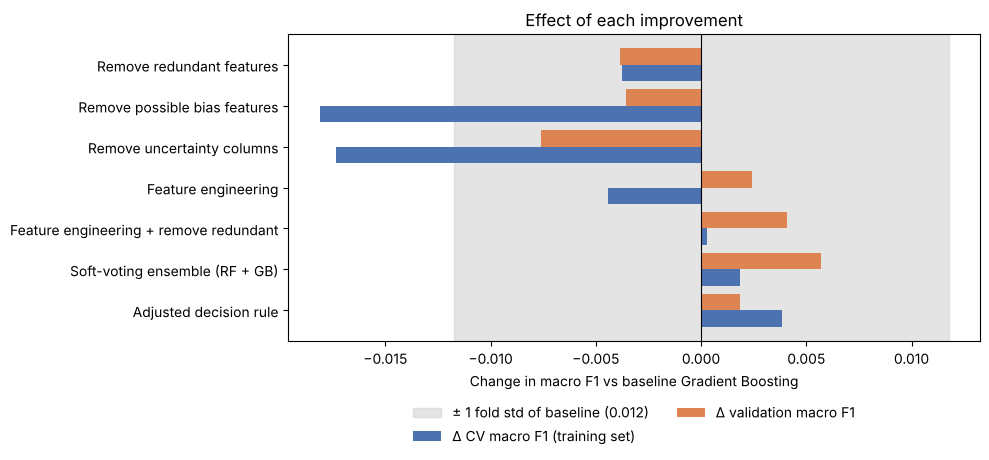

,Features,CV macro F1,CV std,Validation macro F1,Δ CV,Δ validation
Baseline (all 39 features),39,0.747,0.012,0.747,+0.000,+0.000
Remove redundant features,36,0.743,0.012,0.743,-0.004,-0.004
Remove possible bias features,34,0.729,0.014,0.743,-0.018,-0.004
Remove uncertainty columns,19,0.729,0.009,0.739,-0.017,-0.008
Feature engineering,43,0.742,0.020,0.749,-0.004,+0.002
Feature engineering + remove redundant,40,0.747,0.014,0.751,+0.000,+0.004
Soft-voting ensemble (RF + GB),39,0.749,0.011,0.752,+0.002,+0.006
Adjusted decision rule,39,0.751,-,0.748,+0.004,+0.002


In [40]:
exp = pd.DataFrame(experiments).T
base_row = exp.loc["Baseline (all 39 features)"]
exp["Δ CV"] = exp["CV macro F1"] - base_row["CV macro F1"]
exp["Δ validation"] = exp["Validation macro F1"] - base_row["Validation macro F1"]
noise = base_row["CV std"]

plot = exp.drop(index="Baseline (all 39 features)").iloc[::-1]
y_pos = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(-noise, noise, color="lightgrey", alpha=0.6, label=f"± 1 fold std of baseline ({noise:.3f})")
ax.barh(y_pos - 0.2, plot["Δ CV"], height=0.4, color="#4C72B0", label="Δ CV macro F1 (training set)")
ax.barh(y_pos + 0.2, plot["Δ validation"], height=0.4, color="#DD8452", label="Δ validation macro F1")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot.index)
ax.set_xlabel("Change in macro F1 vs baseline Gradient Boosting")
ax.set_title("Effect of each improvement")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

exp.style.format({"Features": "{:.0f}", "CV macro F1": "{:.3f}", "CV std": "{:.3f}", "Validation macro F1": "{:.3f}",
                  "Δ CV": "{:+.3f}", "Δ validation": "{:+.3f}"}, na_rep="-")

## 4.3 Reframing the Problem: Confirmed vs False Positive

Throughout this notebook, CANDIDATE has been the main source of error. It is not a physical category but a *status*: objects that have not yet been resolved into planets or false positives. A different and arguably more useful framing is therefore:

1. Train a **binary** model on resolved objects only (CONFIRMED vs FALSE POSITIVE).
2. Use it to estimate, for each CANDIDATE, the probability that it is a real planet.

This matches how the problem is approached in practice, where the aim is to prioritise candidates for follow-up observation. The same tuned Gradient Boosting settings are used. Because this is a new model, it is scored on the resolved objects of the test set, which it has not seen.

In [41]:
from sklearn.metrics import accuracy_score, roc_auc_score

def resolved(X, y):
    keep = (y != "CANDIDATE").values
    return X[keep], (y[keep] == "CONFIRMED").astype(int)

Xb_trainval, yb_trainval = resolved(X_trainval, y_trainval)
Xb_test, yb_test = resolved(X_test_enc, y_test)

binary_cv = cross_val_score(clone(base_model), *resolved(X_train_enc, y_train), cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"Binary CV macro F1 (training set): {binary_cv.mean():.3f} ± {binary_cv.std():.3f}")

binary_model = clone(base_model).fit(Xb_trainval, yb_trainval)
pb = binary_model.predict_proba(Xb_test)[:, 1]
pred_b = (pb >= 0.5).astype(int)

print()
print("Test set (resolved objects only):")
print(f"  Accuracy:          {accuracy_score(yb_test, pred_b):.3f}")
print(f"  Balanced accuracy: {balanced_accuracy_score(yb_test, pred_b):.3f}")
print(f"  Macro F1:          {f1_score(yb_test, pred_b, average='macro'):.3f}")
print(f"  ROC AUC:           {roc_auc_score(yb_test, pb):.3f}")
print()
print(classification_report(yb_test, pred_b, target_names=["FALSE POSITIVE", "CONFIRMED"], digits=3))

Binary CV macro F1 (training set): 0.938 ± 0.009

Test set (resolved objects only):
  Accuracy:          0.942
  Balanced accuracy: 0.941
  Macro F1:          0.936
  ROC AUC:           0.986

                precision    recall  f1-score   support

FALSE POSITIVE      0.967     0.944     0.955       871
     CONFIRMED      0.897     0.938     0.917       455

      accuracy                          0.942      1326
     macro avg      0.932     0.941     0.936      1326
  weighted avg      0.943     0.942     0.942      1326



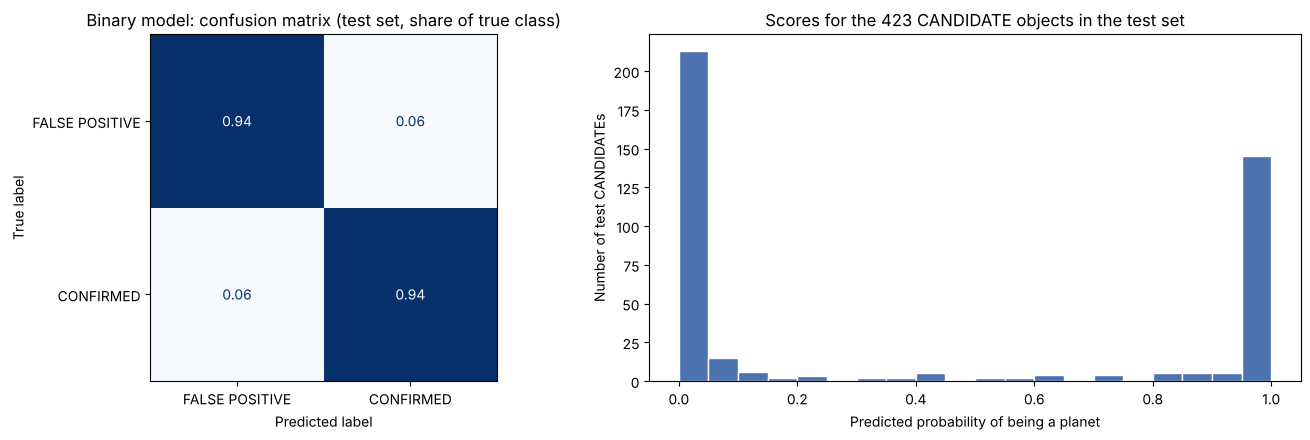

,Candidates,Share
Likely false positive (< 0.1),228,0.539
Leaning false positive (0.1-0.5),22,0.052
Leaning planet (0.5-0.9),23,0.054
Likely planet (≥ 0.9),150,0.355


In [42]:
cand_X = X_test_enc[(y_test == "CANDIDATE").values]
cand_p = binary_model.predict_proba(cand_X)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ConfusionMatrixDisplay.from_predictions(yb_test, pred_b, display_labels=["FALSE POSITIVE", "CONFIRMED"],
                                        normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Binary model: confusion matrix (test set, share of true class)")

axes[1].hist(cand_p, bins=np.linspace(0, 1, 21), color="#4C72B0", edgecolor="white")
axes[1].set_xlabel("Predicted probability of being a planet")
axes[1].set_ylabel("Number of test CANDIDATEs")
axes[1].set_title(f"Scores for the {len(cand_p)} CANDIDATE objects in the test set")
plt.tight_layout()
plt.show()

cand_bands = pd.cut(cand_p, [0, 0.1, 0.5, 0.9, 1.0], include_lowest=True,
                    labels=["Likely false positive (< 0.1)", "Leaning false positive (0.1-0.5)",
                            "Leaning planet (0.5-0.9)", "Likely planet (≥ 0.9)"])
cand_summary = pd.Series(cand_bands).value_counts().reindex(cand_bands.categories).to_frame("Candidates")
cand_summary["Share"] = (cand_summary["Candidates"] / len(cand_p)).round(3)
cand_summary

## 4.4 Conclusion

**Model evaluation**

- **Ranking stability (4.1.1).** Over 10 repeated CV folds, Gradient Boosting averages a macro F1 of 0.745 ± 0.012, against 0.733 for both the tuned Random Forest and the SVM, and 0.705 for Logistic Regression. Gradient Boosting beats the Random Forest in 8 of the 10 paired folds (mean difference +0.011). So the test-set result in Section 3.5.1, where the Random Forest came out on top, was most likely chance from that particular split. Gradient Boosting is a small but consistent winner and remains the final model.
- **Ranking quality (4.1.2).** On the test set, the model ranks objects well for CONFIRMED (ROC AUC 0.954, AP 0.859) and FALSE POSITIVE (AUC 0.934, AP 0.926). CANDIDATE is clearly weaker (AUC 0.827, AP 0.625), although still far above a random model (AP 0.242).
- **Learning curve (4.1.3).** Training F1 is 1.0 at every size, meaning the model fits its training data perfectly, while CV F1 rises from 0.691 to 0.747. The large gap shows the model is complex enough to memorise the training data. However, the CV score is still rising at full size, so more labelled data would very likely improve it further. Stronger regularisation (shallower trees or more `l2_regularization`) is an option, but the tuning grid already preferred unlimited depth over `max_depth=6`.
- **Confidence (4.1.4).** 68% of test objects receive a confidence above 0.95, and the model is right for 88.5% of these. Below 0.9 confidence, accuracy falls to around 50–57%. These low-confidence objects are much more often CANDIDATEs. In practice, the model's confidence could be used to send the uncertain cases (about a third of objects) for manual review.
- **Leakage check (4.1.5).** When all KOIs from the same star are kept in the same fold, cross-validated macro F1 falls from 0.747 to 0.737. Star-level leakage inflates the scores by about one percentage point at most, which is within normal variation.

**Further improvements (4.2)**

None of the seven experiments changed macro F1 by more than the fold-to-fold noise (±0.012).

- **Best results.** The soft-voting ensemble (+0.002 CV, +0.006 validation) and feature engineering combined with removing redundant features (+0.000 CV, +0.004 validation) gave the largest gains. Both are well inside normal variation.
- **Adjusted decision rule.** Boosting the CANDIDATE probability by 1.5× raised CANDIDATE recall, but the overall gain disappeared on the validation set (+0.002).
- **Removing redundant features** costs almost nothing (−0.004), so the model can be simplified from 39 to 36 features without loss.
- **Removing the possible bias features** (`ra`, `dec`, `koi_tce_delivname`) and **removing the uncertainty columns** both lowered the CV score by about 0.018. The model does draw some signal from where an object is on the sky, which data release it came from, and how precisely it was measured. This should be stated as a limitation, as these are not physical properties of planets.
- **The engineered `duration_ratio`** behaved partly as expected: the median is 0.91 for confirmed planets and 1.09 for false positives. However, it added nothing beyond what the trees could already learn from period, duration and the stellar features.

Because no change passed the threshold set in advance, **the Section 3 Gradient Boosting model is kept unchanged**, and its test result (78.0% accuracy, macro F1 0.744) stands as the final three-class result. The test set was not re-used to choose between these experiments.

**Reframing the problem (4.3)**

This was the most valuable result of this section. A binary CONFIRMED vs FALSE POSITIVE model with the same settings reaches **94.2% accuracy, 0.936 macro F1 and a ROC AUC of 0.986** on the test set, with 94% recall for both classes. This confirms that the three-class model's ceiling of around 0.75 comes from the CANDIDATE label rather than from the features or the algorithm.

Applied to the 423 test-set CANDIDATEs, the binary model scores 36% as likely planets (probability ≥ 0.9) and 54% as likely false positives (< 0.1). Only about 11% fall in between. This gives a practical ranking for deciding which candidates to follow up first. One caveat: because the model fits its training data perfectly (4.1.3), its probabilities are likely to be over-confident. They should be calibrated (e.g. with `CalibratedClassifierCV`) before being used as real probabilities.

**Summary**

| Task | Model | Test accuracy | Test macro F1 |
|---|---|---|---|
| 3-class disposition | Gradient Boosting (tuned) | 0.780 | 0.744 |
| Confirmed vs false positive | Gradient Boosting (tuned) | 0.942 | 0.936 |

The features in this dataset separate real planets from false positives very well. The three-class task is limited mainly by the CANDIDATE class, which represents objects still awaiting a decision rather than a distinct type of object.

# 5 Summary & Conclusion

## 5.1 Summary

This notebook set out to classify Kepler Objects of Interest (KOIs) by their disposition (CONFIRMED, CANDIDATE or FALSE POSITIVE), using only the measured properties of each transit signal and its host star.

**Data preparation.** The NASA Exoplanet Archive's KOI cumulative table (9,564 rows, 50 attributes) was cleaned as follows:

- The four identifier columns were removed, along with the two empty `koi_teq` uncertainty columns.
- Six attributes that are derived from the disposition itself (`koi_score`, `koi_pdisposition` and the four false-positive flags) were removed to prevent data leakage.
- 820 rows with missing values were dropped.

The remaining 8,744 rows were split 60/20/20 into stratified training, validation and test sets. All exploratory analysis and every modelling decision used only the training and validation sets.

**Exploratory data analysis.**

- **Univariate:** most signal features are extremely right-skewed. For example, the median planet radius is 2.4 Earth radii but the mean is 137.8. A distinct group of very deep, very large signals exists: 18% of KOIs have radii larger than any known planet.
- **Bivariate:** this group is almost entirely false positives. The transit signal-to-noise ratio was the strongest single feature, and several features were found to be near-duplicates of each other.
- **Multivariate:** combinations of features separate the classes better than any single feature. Confirmed planets and candidates overlap heavily, and there is no straight-line boundary between the classes.

**Modelling.** Nine models were compared:

- a baseline;
- Gaussian Naive Bayes;
- a Decision Tree;
- a Random Forest;
- Logistic Regression;
- K-Nearest Neighbours;
- a Support Vector Machine;
- Gradient Boosting.

The Random Forest appears twice, with default and tuned settings. Each model was tuned with 5-fold stratified cross-validation, using macro F1 so that all three classes count equally. The models that can learn non-linear boundaries performed best. Gradient Boosting was selected on the validation set, and repeated cross-validation confirmed it as a small but consistent winner (macro F1 0.745 against 0.733 for the Random Forest and SVM).

**Further improvements.** Seven attempts were made to improve the final model: three forms of feature removal, two of feature engineering, an ensemble and an adjusted decision rule. None changed performance by more than normal variation, so the Section 3 model was kept. A reframed binary model (CONFIRMED vs FALSE POSITIVE) performed far better.

## 5.2 Final Results

| Task | Model | Test accuracy | Test balanced accuracy | Test macro F1 |
|---|---|---|---|---|
| Baseline (always predicts FALSE POSITIVE) | DummyClassifier | 0.499 | 0.333 | 0.222 |
| 3-class disposition | Gradient Boosting (tuned) | **0.780** | **0.746** | **0.744** |
| Confirmed vs false positive | Gradient Boosting (tuned) | **0.942** | **0.941** | **0.936** |

For the three-class model, per-class F1 on the test set was:

- FALSE POSITIVE: 0.859
- CONFIRMED: 0.808
- CANDIDATE: 0.566

Only 3% of confirmed planets were mistaken for false positives, and only 4% of false positives for confirmed planets. The binary model reached a ROC AUC of 0.986.

## 5.3 Research Questions

| ID | Question | Conclusion | Evidence |
|---|---|---|---|
| RQ1 | Does transit depth differ between confirmed planets and false positives? | **Partly supported** | Medians are similar (476 vs 570 ppm); the difference lies in the extreme tail of very deep false positives. 7th most important feature. |
| RQ2 | Does planet radius differ? | **Supported** | 94% of KOIs larger than 30 Earth radii are false positives. 4th most important feature. |
| RQ3 | Does the impact parameter differ? | **Supported** | 90% of grazing KOIs (impact > 1) are false positives. 5th most important feature. |
| RQ4 | Are confirmed planets more likely to have short orbital periods? | **Rejected** | The opposite holds: false positives have the shortest periods (median 5.2 vs 11.8 days). This is partly but not entirely explained by large, grazing eclipsing binaries. 3rd most important feature. |
| RQ5 | Are KOIs in multi-planet systems more likely to be confirmed? | **Supported** | 49% confirmed in multi-planet systems against 22% for single KOIs; the effect holds after controlling for radius and impact. 14th most important feature. |
| RQ6 | Do host-star properties have little impact? | **Supported** | Negligible to small effect sizes. Star radius and temperature rank 28th and 38th of 39 features. |

## 5.4 Limitations

- **The CANDIDATE class is not a physical category.** It is a status describing objects not yet resolved, so it mixes future planets with future false positives. This limits the three-class model to a macro F1 of around 0.75 regardless of algorithm, as shown by the much higher score of the binary model.
- **Rows removed for missing values were mostly false positives** (81% of the 820 dropped, against 50% overall). The models are therefore not tested on some of the most irregular signals, and their scores may be slightly optimistic.
- **Some predictive signal is not physical.** Sky position (`ra`, `dec`), data release (`koi_tce_delivname`) and measurement-uncertainty columns contribute to performance, and removing them lowered cross-validated macro F1 by about 0.018. The model therefore partly learns how and how precisely an object was observed, not only what it is.
- **Planets from the same star can appear in both training and test sets.** Section 4.1.5 checked this by keeping all KOIs from the same star in the same cross-validation fold. Macro F1 fell from 0.747 to 0.737, so leakage inflates the scores by about one percentage point at most, which is within normal variation.
- **Probabilities are likely to be over-confident.** The selected model fits its training data perfectly, so its probability outputs should be calibrated before they are used for decisions such as prioritising candidates.
- **One held-out test split** was used. With the top three models within about 0.01 of each other, their exact ranking on any single split is not reliable. The repeated cross-validation in Section 4.1.1 is the stronger evidence.
- **`HistGradientBoostingClassifier`** was used in place of the classic `GradientBoostingClassifier` for training speed. It uses the same algorithm, but small differences in results between the two are possible.

## 5.5 Future Work

- **Score the open candidates.** Apply the binary model to all CANDIDATE objects to rank them for follow-up observation, after calibrating its probabilities.
- **Use richer inputs.** Add features from the light curves themselves, for example by training a convolutional neural network on the folded transit signal. This is the approach taken by Shallue and Vanderburg (2018).
- **Validate on newer labels.** Check the model against later dispositions from the NASA Exoplanet Archive to see how well it predicts how candidates are eventually resolved.
- **Test robustness to non-physical features.** Train a version without the non-physical features and with group-aware splitting by star, to give a more conservative estimate of real-world performance.

## 5.6 Conclusion

Machine learning can separate real exoplanets from false positives in the Kepler data with high accuracy: 94.2% when the task is framed as confirmed planet vs false positive. The most informative measurements are the signal-to-noise ratio, transit duration, orbital period, planet radius and impact parameter, which largely agrees with the physical reasoning behind the research questions. The one major surprise was RQ4, where short periods turned out to indicate false positives rather than planets.

When CANDIDATE is included as a third class, performance falls to a macro F1 of 0.744, and further tuning, feature engineering and ensembling did not improve this. The limit therefore lies in the label, not in the choice of algorithm. For this dataset, the most useful model is one that learns from resolved objects and uses that knowledge to estimate which candidates are likely to be real planets.